# HMDA 2024: pipeline Pandas (rules.yaml 1.1)

Notebook này thay cho notebook Pandas cũ, viết lại theo `rules.yaml` 1.1 và bổ sung các phần còn thiếu.

**Chuẩn bị trên Kaggle**
1. Input gồm dataset `hmda-2024-one-year-raw` (`hmda_2024_raw.parquet`) và `hmda-config` (`rules.yaml` bản 1.1, `expected.yaml`).
   Transmittal Sheet lấy từ dataset `hmda-2024-ffiec-files` (Kaggle nhập từ link FFIEC); thiếu file này thì notebook thử tải khi có Internet.
2. Settings: Accelerator = None (CPU), RAM 30 GB. Chạy *Run All*.
3. Kết quả ghi vào `/kaggle/working/results/pandas/` và `/kaggle/working/figures/pandas/`.
   Các file `eq_*.csv` và `key_numbers.json` dùng cho script so sánh với PySpark.

**Thứ tự**: (0) cài đặt, (1) đọc và lọc, (2) tạo biến, (3) kiểm tra số kỳ vọng, (4) SQ1, (5) SQ2,
(6) giá trị kỳ vọng p_ext, (7) SQ3, (8) SQ4, (9) mô hình hai chiều và HHI, (10) đầu ra tương đương,
(11) mô hình dự đoán, (12) tổng kết.

In [1]:
# ===== 0. Cài đặt =====
import os, glob, json, time, shutil, gc, hashlib, math
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import yaml
import matplotlib

try:
    get_ipython  # noqa: F821
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

T_START = time.time()
RUN_DUPLICATES = True      # đếm dòng trùng trên 99 cột (tốn vài phút trên dữ liệu thật)
RUN_PREDICTION = True      # mô hình dự đoán (mục 11)


def find_file(pattern, required=True):
    """Tìm file ở mọi dataset/notebook đã Add Input (hoặc thư mục HMDA_INPUT khi chạy ngoài Kaggle)."""
    roots = [os.environ["HMDA_INPUT"]] if os.environ.get("HMDA_INPUT") else ["/kaggle/input"]
    hits = sorted(h for r_ in roots for h in glob.glob(os.path.join(r_, "**", pattern), recursive=True))
    assert hits or not required, f"Không thấy {pattern} trong {roots}: kiểm tra Add Input"
    return hits[0] if hits else None


RAW_SRC = find_file("hmda_2024_raw.parquet")
RULES_PATH = find_file("rules.yaml")
EXP_PATH = find_file("expected.yaml", required=False)
TS_PATH = find_file("*public_ts*.csv", required=False) or find_file("*public_ts*.zip", required=False)
INP = os.path.dirname(RAW_SRC)
OUTROOT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.environ.get("HMDA_OUT", "output")
RES, FIG = f"{OUTROOT}/results/pandas", f"{OUTROOT}/figures/pandas"
WORK = os.environ.get("HMDA_WORK", "/tmp/hmda")
for d in (RES, FIG, WORK):
    os.makedirs(d, exist_ok=True)

R = yaml.safe_load(open(RULES_PATH, encoding="utf-8"))
assert float(R["version"]) >= 1.1, f"Cần rules.yaml 1.1 trở lên, đang là {R.get('version')}"
if TS_PATH is None and R["source"]["transmittal_sheet"].get("url"):   # chưa có TS trong Input: thử tải từ FFIEC (cần Internet)
    try:
        import urllib.request
        os.makedirs(os.environ.get("HMDA_WORK", "/tmp/hmda"), exist_ok=True)
        TS_PATH = os.path.join(os.environ.get("HMDA_WORK", "/tmp/hmda"), "ts_one_year.zip")
        urllib.request.urlretrieve(R["source"]["transmittal_sheet"]["url"], TS_PATH)
    except Exception as e_:
        print("không tải được Transmittal Sheet:", repr(e_)[:100]); TS_PATH = None
EXP = yaml.safe_load(open(EXP_PATH, encoding="utf-8")) if EXP_PATH else {}

RAW = f"{WORK}/hmda_2024_raw.parquet"
if not os.path.exists(RAW) or os.path.getsize(RAW) != os.path.getsize(RAW_SRC):
    t = time.time(); shutil.copy(RAW_SRC, RAW)
    print(f"đã chép Parquet sang {WORK} ({time.time() - t:.0f}s)")

V, TH, G = R["variables"], R["thresholds"], R["geography"]
LT_NAME = {k: v for k, v in R["codes"]["loan_type"].items()}
LP_NAME = {k: v for k, v in R["codes"]["loan_purpose"].items()}
UNIVERSE = set(G["universe_states"])
KEY = {"rules_version": str(R["version"]), "engine": "pandas"}   # số chính, so với PySpark
CHECKS = []


def exp_value(path):
    node = EXP
    for p in path.split("."):
        if not isinstance(node, dict) or p not in node:
            return None, None, None
        node = node[p]
    return (node.get("value"), node.get("status"), node.get("tol", 1e-9)) if isinstance(node, dict) else (node, None, 1e-9)


def check(label, value, path=None):
    ev, st, tol = exp_value(path) if path else (None, None, None)
    ok = None if (ev is None or value is None or st == "pending") else (abs(float(value) - float(ev)) <= tol * max(1.0, abs(float(ev))))
    CHECKS.append({"check": label, "value": value, "expected": ev, "expected_status": st, "match": ok})
    flag = "" if ok is None else ("  OK" if ok else "  <-- LỆCH")
    print(f"  {label:<44} {value!s:>16}   kỳ vọng {ev!s:>12} ({st}){flag}")


def save(df, name, index=False):
    df.to_csv(f"{RES}/{name}.csv", index=index)


def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.divide(k, n, out=np.full_like(k, np.nan), where=n > 0)
    den = 1 + z ** 2 / n
    ctr = (p + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return ctr - half, ctr + half


def ntile(values, keys, k=5):
    """Giống Spark ntile(k) trên ORDER BY (value, key): k nhóm, các nhóm đầu nhận phần dư."""
    order = np.lexsort((np.asarray(keys), np.asarray(values)))
    n = len(order); base, rem = divmod(n, k)
    sizes = [base + (1 if i < rem else 0) for i in range(k)]
    lab = np.repeat(np.arange(1, k + 1), sizes)
    out = np.empty(n, dtype=int); out[order] = lab
    return out


def spearman(x, y):
    x, y = pd.Series(x).reset_index(drop=True), pd.Series(y).reset_index(drop=True)
    m = x.notna() & y.notna()
    return float(x[m].rank(method="average").corr(y[m].rank(method="average")))


def show():
    if IN_NOTEBOOK:
        plt.show()
    plt.close("all")


print("input :", INP); print("output:", RES); print("rules :", R["version"], "| expected.yaml:", bool(EXP))

đã chép Parquet sang /tmp/hmda (2s)
input : /kaggle/input/datasets/quangvinh7105/hmda-2024-one-year-raw
output: /kaggle/working/results/pandas
rules : 1.1 | expected.yaml: True


## 1. Đọc dữ liệu thô và lọc mẫu core
Một lượt đọc theo khối (200 nghìn dòng) bằng PyArrow, làm đồng thời:
số dòng, cơ cấu `action_taken` trên mọi bản ghi, bảng mã đặc biệt của 10 trường (rules mục 16),
đếm dòng trùng (hash 64-bit trên 99 cột, bỏ `row_id`), và lọc 7 bước của mẫu core (rules mục 4).

In [2]:
t0 = time.time()
pf = pq.ParquetFile(RAW)
ALLCOLS = [c for c in pf.schema_arrow.names if c != "row_id"]
FILT = R["samples"]["core_filters"]
DQ = R["data_quality"]["special_code_table"]
KEEP = ["row_id", "lei", "state_code", "county_code", "derived_msa_md", "action_taken", "loan_type",
        "loan_purpose", "loan_amount", "income", "debt_to_income_ratio", "combined_loan_to_value_ratio",
        "tract_to_msa_income_percentage", "conforming_loan_limit", "submission_of_application",
        "initially_payable_to_institution", "denial_reason_1", "denial_reason_2", "denial_reason_3",
        "denial_reason_4", "rate_spread", "interest_rate", "loan_term", "total_loan_costs"]
NEED = sorted(set(KEEP) | {f["column"] for f in FILT} | set(DQ["fields"]))
READ = ALLCOLS + ["row_id"]          # đọc đủ 99 cột: profiling toàn bộ trường (rules mục 16)
FP = R["data_quality"]["field_profile"]

n_all = 0
act_counts = {}
sc_counts = {(f, c): 0 for f in DQ["fields"] for c in DQ["codes"]}
fp_counts = {(f, c): 0 for f in ALLCOLS for c in FP["count_codes"] + ["numeric"]}
step_counts = {f["step"]: 0 for f in FILT}
open_end_exempt_removed = 0
dup_hashes = []
parts = []
for batch in pf.iter_batches(batch_size=200_000, columns=READ):
    tb = pa.Table.from_batches([batch])
    n_all += tb.num_rows
    for v, cnt in zip(*[x.to_pylist() for x in pc.value_counts(tb["action_taken"]).flatten()]):
        act_counts[v] = act_counts.get(v, 0) + cnt
    for f in DQ["fields"]:
        col = tb[f]
        for code in DQ["codes"]:
            sc_counts[(f, code)] += int(pc.sum(pc.equal(col, code)).as_py() or 0)
    for f in ALLCOLS:
        col = tb[f]
        for code in FP["count_codes"]:
            fp_counts[(f, code)] += int(pc.sum(pc.equal(col, code)).as_py() or 0)
        fp_counts[(f, "numeric")] += int(pc.sum(pc.match_substring_regex(col, FP["numeric_pattern"])).as_py() or 0)
    if RUN_DUPLICATES:
        h = pd.util.hash_pandas_object(tb.select(ALLCOLS).to_pandas(), index=False).to_numpy()
        dup_hashes.append(h)
    for f in FILT:
        col = tb[f["column"]]
        if f["step"] == "closed_end":
            open_end_exempt_removed += int(pc.sum(pc.equal(col, "1111")).as_py() or 0)
        mask = pc.is_in(col, pa.array(f["in"])) if "in" in f else pc.equal(col, f["equals"])
        tb = tb.filter(mask)
        step_counts[f["step"]] += tb.num_rows
    parts.append(tb.select(KEEP))

core_tab = pa.concat_tables(parts); del parts
c = core_tab.to_pandas(strings_to_categorical=True); del core_tab
c["row_id"] = c["row_id"].astype("int64")
n_dup = 0
if RUN_DUPLICATES:
    hh = np.concatenate(dup_hashes); del dup_hashes
    _, cnt = np.unique(hh, return_counts=True)
    n_dup = int((cnt - 1).sum()); del hh
gc.collect()
print(f"đọc {n_all:,} dòng, core {len(c):,} dòng | {time.time() - t0:.0f}s")

đọc 12,259,199 dòng, core 5,775,325 dòng | 266s


## 2. Tạo biến (rules mục 6)
Mọi chuyển đổi số đi qua danh mục (category) nên chỉ chuyển mỗi giá trị khác nhau một lần.
Mã `NA`, `Exempt`, chuỗi rỗng thành NaN; chuỗi lạ khác cũng thành NaN nhưng được đếm và in ra.

In [3]:
t0 = time.time()
NUM_SPECIAL = ["NA", "Exempt", ""]
STRANGE = {}


def to_num(s, name):
    if not isinstance(s.dtype, pd.CategoricalDtype):
        s = s.astype("category")
    cats = pd.Series(s.cat.categories.astype(str))
    vals = pd.to_numeric(cats.where(~cats.isin(NUM_SPECIAL)), errors="coerce").to_numpy(float)
    bad = cats[~cats.isin(NUM_SPECIAL) & np.isnan(vals)]
    if len(bad):
        STRANGE[name] = list(bad[:5])
    codes = s.cat.codes.to_numpy()
    return np.where(codes >= 0, vals[np.clip(codes, 0, None)], np.nan)


def as_str(s):
    return s.astype(str)


def bands(x, spec, cuts=None):
    lo = [b["lo"] for b in spec]; hi = [b["hi"] for b in spec]
    rs = lambda v: cuts[v] if isinstance(v, str) else float(v)
    edges = [rs(lo[0])] + [rs(h) for h in hi]
    return pd.cut(x, bins=edges, labels=[b["label"] for b in spec], right=True)


for col in ["action_taken", "loan_type", "loan_purpose"]:
    c[col] = c[col].astype(str).astype("category")
act = c["action_taken"].astype(str)
c["decisioned"] = act.isin(R["samples"]["decisioned"]["action_taken_in"]).to_numpy()
c["denied"] = (act == "3").to_numpy()
c["orig"] = (act == "1").to_numpy()

# DTI
D = V["debt_to_income_ratio"]
cats = pd.Series(c["debt_to_income_ratio"].cat.categories.astype(str))
norm = cats.str.replace("%", "", regex=False).str.replace(" ", "", regex=False)
dmap = norm.map({str(k): v for k, v in D["ordinal_map"].items()}).to_numpy(float)
codes = c["debt_to_income_ratio"].cat.codes.to_numpy()
c["dti_ordinal"] = np.where(codes >= 0, dmap[np.clip(codes, 0, None)], np.nan)
c["dti_band"] = bands(c["dti_ordinal"], D["bands"])

# CLTV
L = V["combined_loan_to_value_ratio"]
c["cltv"] = to_num(c["combined_loan_to_value_ratio"], "cltv")
c["cltv_valid"] = (c["cltv"] > L["valid_range"]["gt"]) & (c["cltv"] <= L["valid_range"]["le"])
c["cltv_band"] = bands(c["cltv"].where(c["cltv_valid"]), L["bands"])

# Income, loan amount, LTI
c["income_num"] = to_num(c["income"], "income")
c["income_is_na"] = (c["income"].astype(str) == "NA").to_numpy()
c["loan_amount_num"] = to_num(c["loan_amount"], "loan_amount")
inc_ok = c["income_num"] > 0
c["lti"] = np.where(inc_ok, c["loan_amount_num"] / (1000 * c["income_num"]), np.nan)
CUT = V["loan_to_income"]["cut_exact"]
c["lti_band"] = bands(c["lti"], V["loan_to_income"]["bands"], CUT)

c["usable"] = c["decisioned"] & c["dti_ordinal"].notna() & c["cltv_valid"] & inc_ok

# LMI
tr = to_num(c["tract_to_msa_income_percentage"], "tract")
tr = np.where(tr == 0, np.nan, tr) if V["lmi_tract"]["zero_means_missing"] else tr
c["tract_ratio"] = tr
c["lmi"] = pd.array(np.where(np.isnan(tr), None, tr < V["lmi_tract"]["lmi_if_below"]), dtype="boolean")

# jumbo, broker, channel3
def map_flag(col, mapping):
    m = {k: v for k, v in mapping.items() if v is not None}
    return col.astype(str).map(m).astype("Int8")


c["jumbo"] = map_flag(c["conforming_loan_limit"], V["jumbo"]["values"])
c["broker"] = map_flag(c["submission_of_application"], V["broker"]["values"])
sub, pay = c["submission_of_application"].astype(str), c["initially_payable_to_institution"].astype(str)
ch = np.select([sub.isin(["3", "1111"]) | pay.isin(["3", "1111"]), pay == "2",
                (sub == "1") & (pay == "1"), (sub == "2") & (pay == "1")],
               [None, "third_party", "retail", "broker"], default=None)
c["channel3"] = pd.Series(ch, index=c.index, dtype="string")

# Giá
RSV = V["rate_spread"]["valid_range"]
c["rs_num"] = to_num(c["rate_spread"], "rate_spread")
c["rs_valid"] = (c["rs_num"] >= RSV["ge"]) & (c["rs_num"] <= RSV["le"])
c["rs_out_of_range"] = c["rs_num"].notna() & ~c["rs_valid"]
c["pricing"] = c["orig"] & c["rs_valid"]
IRV, LTV_, TCV = V["interest_rate"]["valid_range"], V["loan_term"]["valid_range"], V["total_loan_costs"]["valid_range"]
c["ir_num"] = to_num(c["interest_rate"], "interest_rate")
c["ir_valid"] = (c["ir_num"] >= IRV["ge"]) & (c["ir_num"] <= IRV["le"])
c["term_num"] = to_num(c["loan_term"], "loan_term")
c["term_valid"] = (c["term_num"] > LTV_["gt"]) & (c["term_num"] <= LTV_["le"])
c["tlc_num"] = to_num(c["total_loan_costs"], "total_loan_costs")
c["tlc_valid"] = c["tlc_num"] >= TCV["ge"]
c["cost_share"] = np.where(c["pricing"] & c["tlc_valid"] & (c["loan_amount_num"] > 0),
                           c["tlc_num"] / c["loan_amount_num"], np.nan)
r_m = c["ir_num"] / 1200
n_m = c["term_num"]
with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
    pay_m = np.where(r_m == 0, c["loan_amount_num"] / n_m,
                     c["loan_amount_num"] * r_m / (1 - (1 + r_m) ** (-n_m)))
ok_pti = c["pricing"] & c["ir_valid"] & c["term_valid"] & inc_ok
c["pti"] = np.where(ok_pti, pay_m / (1000 * c["income_num"] / 12), np.nan)

# Địa lý
st = c["state_code"].astype(str)
c["in_universe"] = st.isin(UNIVERSE).to_numpy()
c["state_missing"] = st.isin(G["missing_values"]).to_numpy()
cty = c["county_code"].astype(str)
c["county_valid"] = cty.str.fullmatch(G["county_code_format"].strip("^$")).fillna(False).to_numpy()
c["msa"] = c["derived_msa_md"].astype(str)

# Lý do từ chối: mã số nguyên, rỗng/NA -> 0
for i in range(1, 5):
    c[f"dr{i}"] = np.nan_to_num(to_num(c[f"denial_reason_{i}"], f"denial_reason_{i}"), nan=0).astype("int8")

print("chuỗi lạ khi chuyển số:", STRANGE or "không có")
print(f"tạo biến xong | {time.time() - t0:.0f}s")

chuỗi lạ khi chuyển số: không có
tạo biến xong | 21s


## 3. Kiểm tra với expected.yaml
Cột "kỳ vọng" lấy từ expected.yaml; `OK` nghĩa là khớp tuyệt đối. Số trạng thái `pending` chưa có giá trị để so.

In [4]:
dec = c.loc[c["decisioned"], ["income_is_na", "income_num", "cltv", "cltv_valid", "dti_ordinal"]]
u_mask = c["usable"].to_numpy()
print("Cỡ mẫu:")
check("all_records", n_all, "rows.all_records")
for f in FILT:
    check(f"core_filters.{f['step']}", step_counts[f["step"]], f"core_filters.{f['step']}")
check("open_end_exempt_removed", open_end_exempt_removed, "core_filters.open_end_exempt_removed")
check("decisioned", int(c["decisioned"].sum()), "samples.decisioned")
check("usable", int(u_mask.sum()), "samples.usable")
check("dev_sample_1pct", int(((((c["row_id"] * R["sampling"]["hash_multiplier"]) % R["sampling"]["hash_modulus"])
                               % R["sampling"]["buckets"]) < R["sampling"]["dev_sample_bucket_lt"]).sum()),
      "samples.dev_sample_1pct")
print("Income (decisioned):")
check("income NA", int(dec["income_is_na"].sum()), "income.na_decisioned")
check("income <= 0", int((dec["income_num"] <= 0).sum()), "income.non_positive_decisioned")
check("income > 10000", int((dec["income_num"] > V["income"]["flag_above"]).sum()), "income.above_10000_decisioned")
print("Địa lý:")
check("state codes in core (kể cả NA)", int(c["state_code"].nunique()), "geography.state_codes_in_core")
check("county codes in core (kể cả NA)", int(c["county_code"].nunique()), "geography.county_codes_in_core")
check("county codes hợp lệ (5 chữ số)", int(c.loc[c["county_valid"], "county_code"].nunique()), "geography.county_codes_valid")
check("MSA codes in core (kể cả 99999)", int(c["msa"].nunique()), "geography.msa_codes_in_core")
check("MSA thật (bỏ 99999)", int(c.loc[c["msa"] != R["special_codes"]["msa_nonmetro"], "msa"].nunique()), "geography.msa_codes_real")
for s_ in ["PR", "GU", "VI"]:
    check(f"usable {s_}", int((u_mask & (c["state_code"].astype(str) == s_)).sum()), f"geography.usable_{s_}")
check("thiếu bang, usable", int((u_mask & c["state_missing"]).sum()), "geography.missing_state_usable")
check("thiếu bang, decisioned", int((c["decisioned"] & c["state_missing"]).sum()), "geography.missing_state_decisioned")
print("Rate spread (core, đã giải ngân):")
o_ = c.loc[c["orig"], ["rs_num", "rate_spread", "rs_out_of_range"]]
check("rate_spread dạng số", int(o_["rs_num"].notna().sum()), "rate_spread_pricing.numeric")
check("rate_spread NA", int((o_["rate_spread"].astype(str) == "NA").sum()), "rate_spread_pricing.na")
check("rate_spread Exempt", int((o_["rate_spread"].astype(str) == "Exempt").sum()), "rate_spread_pricing.exempt")
check("rate_spread ngoài [-8, 15]", int(o_["rs_out_of_range"].sum()), "rate_spread_pricing.outside_valid_range")
check("|rate_spread| > 10", int((o_["rs_num"].abs() > 10).sum()), "rate_spread_pricing.abs_above_10")
check("pricing ∩ usable", int((c["pricing"] & c["usable"]).sum()), "rate_spread_pricing.pricing_usable")
share_out = float(o_["rs_out_of_range"].sum() / max(o_["rs_num"].notna().sum(), 1))
print(f"  tỷ lệ ngoài khoảng: {share_out:.6%} (điều kiện dừng 0.01%: {'VƯỢT, báo Vinh' if share_out > 1e-4 else 'không vượt'})")

KEY.update({"all_records": n_all, "core": len(c), "decisioned": int(c["decisioned"].sum()), "usable": int(u_mask.sum()),
            "pricing": int(c["pricing"].sum()), "pricing_usable": int((c["pricing"] & c["usable"]).sum()),
            "duplicates": n_dup, "rs_out_of_range": int(o_["rs_out_of_range"].sum())})
del o_

# Bảng chất lượng dữ liệu
dq = pd.DataFrame([{"field": f, "code": (code if code else "(empty)"), "count": n} for (f, code), n in sc_counts.items()])
save(dq, "dq_special_codes")
fprof = pd.DataFrame([{"field": f, **{(c if c else "(empty)"): fp_counts[(f, c)] for c in FP["count_codes"] + ["numeric"]}}
                      for f in ALLCOLS])
fprof["n"] = n_all
for c_ in [x if x else "(empty)" for x in FP["count_codes"]] + ["numeric"]:
    fprof[f"share_{c_}"] = fprof[c_] / n_all
save(fprof, "dq_field_profile")
print("Trường có nhiều mã NA nhất:\n", fprof.sort_values("NA", ascending=False)[["field", "NA", "share_NA", "Exempt", "numeric"]].head(12).to_string(index=False))
dq_rows = [
    {"item": "exact duplicate rows (99 fields, all records)", "n": n_dup},
    {"item": "decisioned: income NA", "n": int(dec["income_is_na"].sum())},
    {"item": "decisioned: income <= 0", "n": int((dec["income_num"] <= 0).sum())},
    {"item": "decisioned: income > 10,000 (flag only)", "n": int((dec["income_num"] > 10000).sum())},
    {"item": "decisioned: CLTV numeric but outside (0, 250]", "n": int((dec["cltv"].notna() & ~dec["cltv_valid"]).sum())},
    {"item": "decisioned: DTI missing", "n": int(dec["dti_ordinal"].isna().sum())},
    {"item": "core: county_code not 5 digits", "n": int((~c["county_valid"]).sum())},
    {"item": "core: tract ratio 0 (treated as missing)", "n": int(np.isnan(c["tract_ratio"]).sum())},
    {"item": "core originations: rate_spread outside [-8, 15]", "n": KEY["rs_out_of_range"]},
]
save(pd.DataFrame(dq_rows), "dq_summary")
print(pd.DataFrame(dq_rows).to_string(index=False))

# Vì sao hồ sơ withdrawn/incomplete không dùng được để chuẩn hóa: DTI, CLTV là NA theo quy định khi chưa có quyết định
miss = (c.assign(dti_missing=c["dti_ordinal"].isna(), cltv_invalid=~c["cltv_valid"], income_bad=~inc_ok)
          .groupby(as_str(c["action_taken"]))[["dti_missing", "cltv_invalid", "income_bad"]].mean() * 100).round(1)
miss["n"] = c.groupby(as_str(c["action_taken"])).size()
save(miss.reset_index(names="action_taken"), "dq_missing_by_action")
print("\n% thiếu theo action_taken (core):\n", miss.to_string())

Cỡ mẫu:
  all_records                                          12259199   kỳ vọng     12259199 (verified)  OK
  core_filters.applications                            10781992   kỳ vọng     10781992 (single)  OK
  core_filters.first_lien                               7981147   kỳ vọng      7981147 (single)  OK
  core_filters.closed_end                               7258042   kỳ vọng      7258042 (single)  OK
  core_filters.non_business                             6694328   kỳ vọng      6694328 (single)  OK
  core_filters.non_reverse                              6690389   kỳ vọng      6690389 (single)  OK
  core_filters.site_built_1_4_unit                      6088849   kỳ vọng      6088849 (single)  OK
  core_filters.principal_residence                      5775325   kỳ vọng      5775325 (verified)  OK
  open_end_exempt_removed                                216601   kỳ vọng       216601 (single)  OK
  decisioned                                            4514505   kỳ vọng      4514505 (

## 4. SQ1: kết quả hồ sơ, tỷ lệ từ chối theo loại vay và mục đích
Tỷ lệ từ chối = n3 / (n1 + n2 + n3) trên mẫu decisioned. Khoảng Wilson 95% tính cho mọi nhóm; rules chỉ yêu cầu
hiển thị khi mẫu số < 1.000.

tỷ lệ từ chối core: 0.1543
        type  n_decisioned  denial_rate
conventional       2853885       0.1325
         FHA       1027254       0.2176
          VA        595980       0.1521
        USDA         37386       0.1206
           purpose  n_decisioned  denial_rate
          purchase       3140857       0.0881
         refinance        497811       0.1977
cash_out_refinance        716739       0.3516
  home_improvement         56769       0.4388
             other        101936       0.4355
    not_applicable           393       0.7684


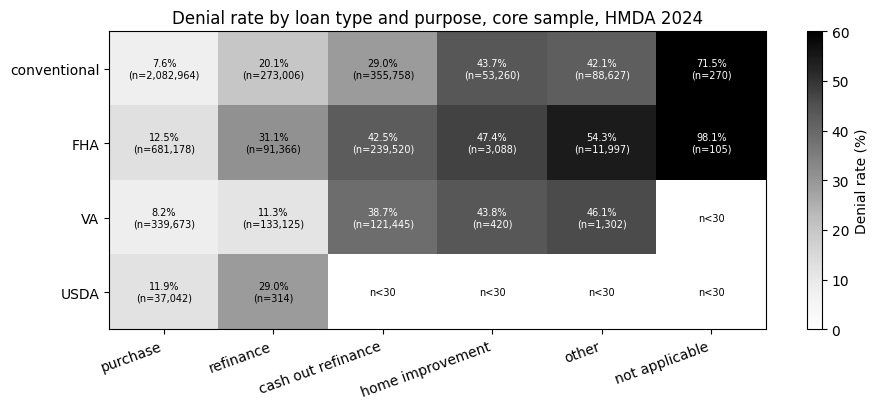

In [5]:
c["type"] = as_str(c["loan_type"]).map(LT_NAME)
c["purpose"] = as_str(c["loan_purpose"]).map(LP_NAME)
dec = c.loc[c["decisioned"], ["type", "purpose", "denied"]]
TYPE_ORDER = ["conventional", "FHA", "VA", "USDA"]
PURP_ORDER = ["purchase", "refinance", "cash_out_refinance", "home_improvement", "other", "not_applicable"]


def denial_table(df, keys):
    g = df.groupby(keys, observed=True).agg(n_decisioned=("denied", "size"), n_denied=("denied", "sum")).reset_index()
    g["denial_rate"] = g["n_denied"] / g["n_decisioned"]
    lo, hi = wilson(g["n_denied"], g["n_decisioned"])
    g["ci_low"], g["ci_high"] = lo, hi
    g["show_ci"] = g["n_decisioned"] < R["data_quality"]["wilson_interval"]["apply_when_denominator_below"]
    return g


out_mix = pd.crosstab(c["type"], as_str(c["action_taken"]).map(R["codes"]["action_taken"]))
out_pct = out_mix.div(out_mix.sum(axis=1), axis=0).reindex(TYPE_ORDER)
out_pct["n_applications"] = out_mix.sum(axis=1)
save(out_pct.reset_index(), "sq1_outcomes_by_type")
by_type = denial_table(dec, ["type"]).set_index("type").reindex(TYPE_ORDER).reset_index()
by_purp = denial_table(dec, ["purpose"]).set_index("purpose").reindex(PURP_ORDER).reset_index()
cross = denial_table(dec, ["type", "purpose"])
save(by_type, "sq1_denial_by_type"); save(by_purp, "sq1_denial_by_purpose"); save(cross, "sq1_denial_type_x_purpose")
o = c.loc[c["orig"], ["type", "loan_amount_num"]]
amt = (o.groupby("type")["loan_amount_num"].agg(n="count", mean="mean", median="median",
                                                 p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75))
         .reindex(TYPE_ORDER).reset_index())
save(amt, "sq1_loan_amount_originated_by_type")
KEY["denial_rate_core"] = float(dec["denied"].mean())
for _, r in by_type.iterrows():
    KEY[f"denial_rate_{r['type']}"] = float(r["denial_rate"])
print(f"tỷ lệ từ chối core: {KEY['denial_rate_core']:.4f}")
print(by_type[["type", "n_decisioned", "denial_rate"]].round(4).to_string(index=False))
print(by_purp[["purpose", "n_decisioned", "denial_rate"]].round(4).to_string(index=False))

piv = cross.pivot(index="type", columns="purpose", values="denial_rate").reindex(index=TYPE_ORDER, columns=PURP_ORDER) * 100
npv = cross.pivot(index="type", columns="purpose", values="n_decisioned").reindex(index=TYPE_ORDER, columns=PURP_ORDER)
piv = piv.where(npv >= TH["cell"]["min_n"])
fig, ax = plt.subplots(figsize=(9.5, 4.2))
im = ax.imshow(piv.values.astype(float), cmap="Greys", aspect="auto", vmin=0, vmax=60)
ax.set_xticks(range(len(PURP_ORDER))); ax.set_xticklabels([p.replace("_", " ") for p in PURP_ORDER], rotation=20, ha="right")
ax.set_yticks(range(len(TYPE_ORDER))); ax.set_yticklabels(TYPE_ORDER)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v, n_ = piv.values[i, j], npv.values[i, j]
        ax.text(j, i, "n<30" if np.isnan(v) else f"{v:.1f}%\n(n={int(n_):,})", ha="center", va="center", fontsize=7,
                color="white" if (not np.isnan(v) and v > 35) else "black")
ax.set_title("Denial rate by loan type and purpose, core sample, HMDA 2024")
fig.colorbar(im, ax=ax, label="Denial rate (%)"); plt.tight_layout()
plt.savefig(f"{FIG}/sq1_denial_type_purpose.png", dpi=150); show()

## 5. SQ2: rủi ro, lý do từ chối, phân rã Kitagawa, giá
- H2 dùng thang DTI 19 mức (không dùng nhóm).
- Lý do từ chối: hồ sơ denied trong mẫu usable; một hồ sơ "nêu" lý do k nếu bất kỳ cột nào trong 4 cột bằng k.
- Kitagawa: 75 ô rủi ro, chỉ các ô có >= 30 hồ sơ ở cả hai nhóm; báo thêm chênh tại cơ cấu từng nhóm.

       jump    role    step  baseline_step  excess  ci_low  ci_high
49 -> 50-60    main  0.1639        -0.0001  0.1641  0.1623   0.1658
   42 -> 43   check  0.0000        -0.0001  0.0002 -0.0018   0.0021
   44 -> 45   check  0.0047        -0.0001  0.0049  0.0029   0.0069
   39 -> 40 placebo -0.0015        -0.0001 -0.0013 -0.0034   0.0007
   46 -> 47 placebo -0.0027        -0.0001 -0.0026 -0.0047  -0.0005
scope   n_49  mean_n_44_48  bunching_ratio
    1 183248      108001.0           1.697
    2  45372       39024.2           1.163
    3  14933       13565.2           1.101
  all 243624      160938.4           1.514
             n  denial_rate  median_income  median_loan_amount  median_lti
dti                                                                       
20-<30  539267        0.097          138.0            265000.0       1.973
30-<36  592709        0.088          120.0            295000.0       2.500
<20     171146        0.166          186.0            225000.0       1.136
  

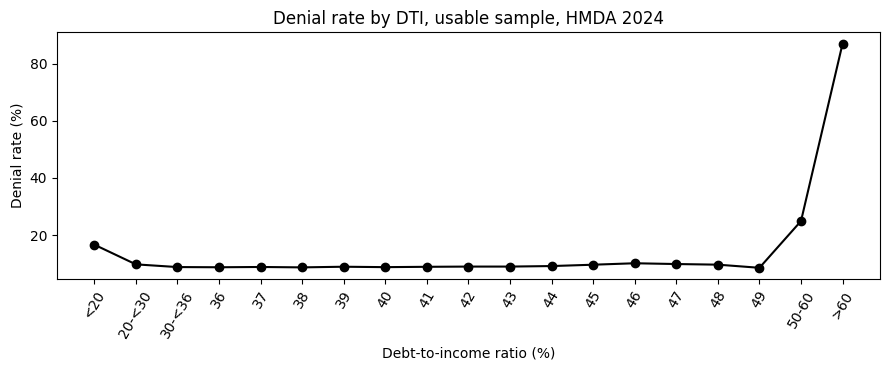

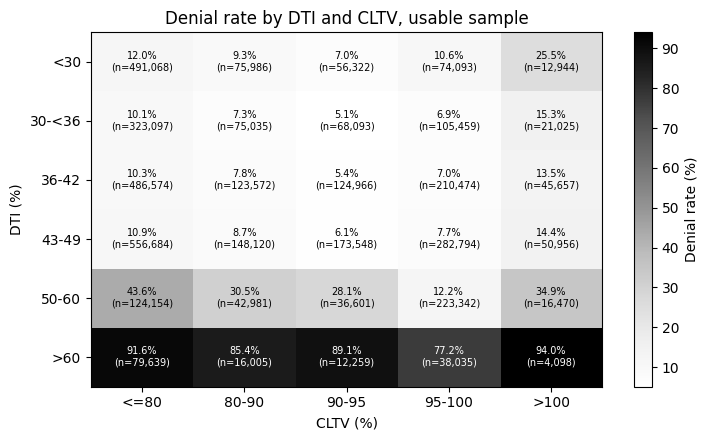


% hồ sơ bị từ chối nêu credit history: cash-out 0.289242776927506 | purchase 0.16195852330752097

Kitagawa (điểm %):
                label   gap  composition  rate  rate_gap_at_a_mix  rate_gap_at_b_mix  cells_a_higher  cells_a_lower  n_common_cells  coverage_a  coverage_b
  FHA vs conventional  8.00         6.73  1.26             -12.41              14.94              54             36              90    1.000000    1.000000
 cash-out vs purchase 22.69         0.67 22.03              17.46              26.60              88              2              90    1.000000    1.000000
refinance vs purchase 12.86        -3.03 15.90              11.46              20.33              87              1              88    0.999873    0.999853
ô rủi ro: 90 | nhỏ nhất 311 | FHA nhỏ nhất 75
  số ô rủi ro                                                90   kỳ vọng           90 (verified)  OK
  ô rủi ro nhỏ nhất                                         311   kỳ vọng          311 (verified)  OK
  FHA ít

In [6]:
UCOLS = ["row_id", "lei", "state_code", "county_code", "msa", "in_universe", "state_missing", "county_valid", "lmi",
         "loan_type", "loan_purpose", "type", "purpose", "denied", "dti_ordinal", "dti_band", "cltv", "cltv_band", "lti",
         "lti_band", "loan_amount_num", "income_num", "dr1", "dr2", "dr3", "dr4"]
U = c.loc[c["usable"], UCOLS].copy()
U["y"] = U["denied"].astype(float)
KEYS = ["dti_band", "cltv_band", "lti_band"]
DTI_LAB = [b["label"] for b in D["bands"]]; CLTV_LAB = [b["label"] for b in L["bands"]]
LTI_LAB = [b["label"] for b in V["loan_to_income"]["bands"]]

inv = {v: k for k, v in D["ordinal_map"].items()}
curve = U.groupby("dti_ordinal")["y"].agg(n="size", denial_rate="mean").reset_index()
curve["dti"] = curve["dti_ordinal"].astype(int).map(inv)
save(curve, "sq2_denial_by_dti_19")


def jump_tests(cnt):
    """cnt: cột scope, level, n, k. Kiểm định bước nhảy DTI (rules mục 21)."""
    J = R["dti_jump_test"]; z = J["ci_z"]; lv = J["levels"]; l36, l49 = lv[0], lv[-2]
    rows, bunch = [], []
    for scope, g in cnt.groupby("scope"):
        g = g.set_index("level")
        if not all(l in g.index for l in lv):
            continue
        r = (g["k"] / g["n"]).to_dict(); n = g["n"].to_dict()
        base = (r[l49] - r[l36]) / (l49 - l36)
        for jp in J["jumps"]:
            coef = {}
            for l, c_ in [(jp["to"], 1.0), (jp["from"], -1.0), (l49, -1.0 / (l49 - l36)), (l36, 1.0 / (l49 - l36))]:
                coef[l] = coef.get(l, 0.0) + c_
            est = sum(c_ * r[l] for l, c_ in coef.items())
            se = math.sqrt(sum(c_ * c_ * r[l] * (1 - r[l]) / n[l] for l, c_ in coef.items()))
            rows.append({"scope": scope, "jump": jp["label"], "role": jp["role"], "rate_from": r[jp["from"]], "rate_to": r[jp["to"]],
                         "step": r[jp["to"]] - r[jp["from"]], "baseline_step": base, "excess": est, "se": se,
                         "ci_low": est - z * se, "ci_high": est + z * se, "n_from": n[jp["from"]], "n_to": n[jp["to"]]})
        bunch.append({"scope": scope, "n_49": n[l49], "mean_n_44_48": float(np.mean([n[l] for l in range(l49 - 5, l49)])),
                      "bunching_ratio": n[l49] / float(np.mean([n[l] for l in range(l49 - 5, l49)]))})
    return pd.DataFrame(rows), pd.DataFrame(bunch)


JL = R["dti_jump_test"]["levels"]
uj = U[U["dti_ordinal"].isin(JL)]
cnt_all = uj.groupby("dti_ordinal")["y"].agg(n="size", k="sum").reset_index().assign(scope="all")
cnt_t = (uj[uj["loan_type"].astype(str).isin([x for x in R["dti_jump_test"]["by"] if x != "all"])]
         .groupby([uj["loan_type"].astype(str).rename("scope"), "dti_ordinal"], observed=True)["y"].agg(n="size", k="sum").reset_index())
jcnt = pd.concat([cnt_all, cnt_t])[["scope", "dti_ordinal", "n", "k"]].rename(columns={"dti_ordinal": "level"})
jcnt["level"] = jcnt["level"].astype(int); jcnt["k"] = jcnt["k"].astype(float)
jt, jb = jump_tests(jcnt)
lo_, hi_ = wilson(jcnt["k"], jcnt["n"]); jcnt["rate"] = jcnt["k"] / jcnt["n"]; jcnt["ci_low"], jcnt["ci_high"] = lo_, hi_
jcnt["dti"] = jcnt["level"].map(inv)
save(jcnt.sort_values(["scope", "level"]), "sq2_dti_jump_table"); save(jt, "sq2_dti_jump_test"); save(jb, "sq2_dti_bunching")
print(jt[jt["scope"] == "all"][["jump", "role", "step", "baseline_step", "excess", "ci_low", "ci_high"]].round(4).to_string(index=False))
print(jb.round(3).to_string(index=False))
for _, r_ in jt.iterrows():
    tag = f"jump_{r_['scope']}_{r_['jump'].replace(' -> ', '_to_').replace('-', '')}"
    KEY[f"{tag}_excess"], KEY[f"{tag}_ci_low"], KEY[f"{tag}_ci_high"] = r_["excess"], r_["ci_low"], r_["ci_high"]
for _, r_ in jb.iterrows():
    KEY[f"bunching_49_{r_['scope']}"] = r_["bunching_ratio"]

# Chẩn đoán DTI dưới 20% (rules mục 22)
LL = R["dti_low_diagnostic"]["levels"]
ul = U[U["dti_ordinal"].isin(LL)].copy(); ul["dti"] = ul["dti_ordinal"].astype(int).map(inv)
t1 = ul.groupby(["dti", "type", "purpose"], observed=True)["y"].agg(n="size", k="sum").reset_index()
t1["rate"] = t1["k"] / t1["n"]; t1["ci_low"], t1["ci_high"] = wilson(t1["k"], t1["n"])
save(t1, "sq2_low_dti_by_type_purpose")
dl_ = ul[ul["denied"]]
RNX = {int(a): b for a, b in R["codes"]["denial_reason"].items() if a not in R["denial_reasons"]["exclude_codes"]}
t2 = pd.DataFrame({nm: (dl_[["dr1", "dr2", "dr3", "dr4"]] == code).any(axis=1).groupby(dl_["dti"]).mean() for code, nm in RNX.items()})
t2["n_denied"] = dl_.groupby("dti").size(); save(t2.reset_index(), "sq2_low_dti_reasons")
t3 = ul.groupby("dti").agg(n=("y", "size"), denial_rate=("y", "mean"), median_income=("income_num", "median"),
                           median_loan_amount=("loan_amount_num", "median"), median_lti=("lti", "median"), median_cltv=("cltv", "median"))
t3 = t3.join(pd.crosstab(ul["dti"], ul["type"], normalize="index").add_prefix("share_")).join(
    pd.crosstab(ul["dti"], ul["purpose"], normalize="index").add_prefix("share_"))
save(t3.reset_index(), "sq2_low_dti_profile")
print(t3[["n", "denial_rate", "median_income", "median_loan_amount", "median_lti"]].round(3).to_string())
for d_, r_ in t3.iterrows():
    KEY[f"low_dti_{d_}_denial_rate"] = float(r_["denial_rate"]); KEY[f"low_dti_{d_}_median_income"] = float(r_["median_income"])
for d_, r_ in t2.iterrows():
    KEY[f"low_dti_{d_}_reason_credit_history"] = float(r_["credit_history"]); KEY[f"low_dti_{d_}_reason_collateral"] = float(r_["collateral"])
del ul, dl_, uj
print(curve[["dti", "n", "denial_rate"]].assign(denial_rate=lambda d: (100 * d["denial_rate"]).round(2)).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(len(curve)), 100 * curve["denial_rate"], marker="o", color="black")
ax.set_xticks(range(len(curve))); ax.set_xticklabels(curve["dti"], rotation=60)
ax.set_xlabel("Debt-to-income ratio (%)"); ax.set_ylabel("Denial rate (%)")
ax.set_title("Denial rate by DTI, usable sample, HMDA 2024"); plt.tight_layout()
plt.savefig(f"{FIG}/sq2_denial_by_dti.png", dpi=150); show()

for k, lab in [("dti_band", DTI_LAB), ("cltv_band", CLTV_LAB), ("lti_band", LTI_LAB)]:
    tb_ = U.groupby(k, observed=True)["y"].agg(n="size", denial_rate="mean").reindex(lab).reset_index()
    save(tb_, f"sq2_denial_by_{k}")
hm = U.groupby(["dti_band", "cltv_band"], observed=True)["y"].agg(n="size", rate="mean").reset_index()
save(hm, "sq2_heatmap_dti_cltv")
P_ = hm.pivot(index="dti_band", columns="cltv_band", values="rate").reindex(index=DTI_LAB, columns=CLTV_LAB) * 100
N_ = hm.pivot(index="dti_band", columns="cltv_band", values="n").reindex(index=DTI_LAB, columns=CLTV_LAB)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
im = ax.imshow(P_.values.astype(float), cmap="Greys", aspect="auto")
ax.set_xticks(range(len(CLTV_LAB))); ax.set_xticklabels(CLTV_LAB); ax.set_yticks(range(len(DTI_LAB))); ax.set_yticklabels(DTI_LAB)
for i in range(P_.shape[0]):
    for j in range(P_.shape[1]):
        v = P_.values[i, j]
        ax.text(j, i, f"{v:.1f}%\n(n={int(N_.values[i, j]):,})", ha="center", va="center", fontsize=7,
                color="white" if v > 50 else "black")
ax.set_xlabel("CLTV (%)"); ax.set_ylabel("DTI (%)"); ax.set_title("Denial rate by DTI and CLTV, usable sample")
fig.colorbar(im, ax=ax, label="Denial rate (%)"); plt.tight_layout()
plt.savefig(f"{FIG}/sq2_heatmap_dti_cltv.png", dpi=150); show()

# Lý do từ chối
RN = {int(k): v for k, v in R["codes"]["denial_reason"].items()}
excl = {int(x) for x in R["denial_reasons"]["exclude_codes"]}
den = U[U["denied"]].copy()
RC = ["dr1", "dr2", "dr3", "dr4"]
for r in sorted(set(RN) - excl):
    den[RN[r]] = (den[RC] == r).any(axis=1)
RNAMES = [RN[r] for r in sorted(set(RN) - excl)]
for by in ["type", "purpose", "dti_band"]:
    t_ = den.groupby(by, observed=True)[RNAMES].mean().reset_index()
    t_["n_denied"] = den.groupby(by, observed=True).size().to_numpy()
    save(t_, f"sq2_reasons_by_{by}")
rp = den.groupby("purpose", observed=True)[RNAMES].mean()
KEY["reason_credit_history_cashout"] = float(rp.loc["cash_out_refinance", "credit_history"]) if "cash_out_refinance" in rp.index else None
KEY["reason_credit_history_purchase"] = float(rp.loc["purchase", "credit_history"]) if "purchase" in rp.index else None
print("\n% hồ sơ bị từ chối nêu credit history: cash-out", KEY["reason_credit_history_cashout"], "| purchase", KEY["reason_credit_history_purchase"])


def kitagawa(d, col, a, b, y="y", keys=KEYS, min_n=TH["cell"]["min_n"]):
    """Phân rã chênh trung bình y giữa nhóm a và b trên các ô rủi ro (rules mục 11)."""
    sub = d[d[col].astype(str).isin([a, b])]
    t = sub.groupby(keys + [sub[col].astype(str).rename("grp")], observed=True)[y].agg(n="size", r="mean").reset_index()
    A = t[t["grp"] == a].set_index(keys)[["n", "r"]]; B = t[t["grp"] == b].set_index(keys)[["n", "r"]]
    j = A.join(B, lsuffix="_a", rsuffix="_b", how="outer")
    nA, nB = j["n_a"].sum(), j["n_b"].sum()
    ok = (j["n_a"] >= min_n) & (j["n_b"] >= min_n)
    jc = j[ok]
    if len(jc) == 0:   # không có ô chung: không phân rã được
        return {"a": a, "b": b, "n_common_cells": 0, "coverage_a": 0.0, "coverage_b": 0.0, "coverage_ge_50pct": False,
                **{k: np.nan for k in ["gap", "composition", "rate", "rate_gap_at_a_mix", "rate_gap_at_b_mix", "min_cell_n_a",
                                       "min_cell_n_b", "within_cell_gap_min", "within_cell_gap_max", "cells_a_higher",
                                       "cells_a_lower", "raw_gap", "sign_flip"]}}
    sA, sB = jc["n_a"] / jc["n_a"].sum(), jc["n_b"] / jc["n_b"].sum()
    rA, rB = jc["r_a"], jc["r_b"]; dr = rA - rB
    res = {"a": a, "b": b, "gap": float((sA * rA).sum() - (sB * rB).sum()),
           "composition": float(((sA - sB) * (rA + rB) / 2).sum()), "rate": float((dr * (sA + sB) / 2).sum()),
           "rate_gap_at_a_mix": float((sA * dr).sum()), "rate_gap_at_b_mix": float((sB * dr).sum()),
           "n_common_cells": int(ok.sum()), "coverage_a": float(jc["n_a"].sum() / nA), "coverage_b": float(jc["n_b"].sum() / nB),
           "min_cell_n_a": int(jc["n_a"].min()), "min_cell_n_b": int(jc["n_b"].min()),
           "within_cell_gap_min": float(dr.min()), "within_cell_gap_max": float(dr.max()),
           "cells_a_higher": int((dr > 0).sum()), "cells_a_lower": int((dr < 0).sum()),
           "raw_gap": float(sub.loc[sub[col].astype(str) == a, y].mean() - sub.loc[sub[col].astype(str) == b, y].mean())}
    res["sign_flip"] = bool(np.sign(res["rate_gap_at_a_mix"]) != np.sign(res["rate_gap_at_b_mix"]))
    res["coverage_ge_50pct"] = bool(min(res["coverage_a"], res["coverage_b"]) >= 0.5)
    return res


kt = []
for p_ in R["kitagawa"]["pairs"]:
    r = kitagawa(U, p_["column"], p_["a"], p_["b"]); r["label"] = p_["label"]; r["column"] = p_["column"]; kt.append(r)
kt = pd.DataFrame(kt)
save(kt, "sq2_kitagawa_denial")
print("\nKitagawa (điểm %):")
print(kt[["label", "gap", "composition", "rate", "rate_gap_at_a_mix", "rate_gap_at_b_mix", "cells_a_higher",
          "cells_a_lower", "n_common_cells", "coverage_a", "coverage_b"]]
      .assign(**{k: lambda d, k=k: (100 * d[k]).round(2) for k in ["gap", "composition", "rate", "rate_gap_at_a_mix", "rate_gap_at_b_mix"]})
      .to_string(index=False))
for _, r in kt.iterrows():
    tag = f"{r['column']}_{r['a']}v{r['b']}"
    for k in ["gap", "composition", "rate", "rate_gap_at_a_mix", "rate_gap_at_b_mix", "within_cell_gap_min",
              "within_cell_gap_max", "cells_a_higher", "cells_a_lower", "n_common_cells", "min_cell_n_a"]:
        KEY[f"kitagawa_{tag}_{k}"] = r[k] if not isinstance(r[k], (np.integer,)) else int(r[k])
KEY["n_risk_cells"] = int(U.groupby(KEYS, observed=True).ngroups)
cells_ = U.groupby(KEYS, observed=True).agg(n=("y", "size"), fha=("loan_type", lambda s: int((s.astype(str) == "2").sum())))
KEY["smallest_cell_n"] = int(cells_["n"].min()); KEY["min_fha_per_cell"] = int(cells_["fha"].min())
save(cells_.reset_index(), "sq2_risk_cells")
print(f"ô rủi ro: {KEY['n_risk_cells']} | nhỏ nhất {KEY['smallest_cell_n']} | FHA nhỏ nhất {KEY['min_fha_per_cell']}")
check("số ô rủi ro", KEY["n_risk_cells"], "risk_cells.n_cells")
check("ô rủi ro nhỏ nhất", KEY["smallest_cell_n"], "risk_cells.smallest_cell_n")
check("FHA ít nhất mỗi ô", KEY["min_fha_per_cell"], "risk_cells.min_fha_per_cell")
check("Kitagawa FHA vs conv: gap", KEY["kitagawa_loan_type_2v1_gap"], "kitagawa_fha_vs_conventional.gap")
check("Kitagawa FHA vs conv: composition", KEY["kitagawa_loan_type_2v1_composition"], "kitagawa_fha_vs_conventional.composition")
check("Kitagawa FHA vs conv: rate", KEY["kitagawa_loan_type_2v1_rate"], "kitagawa_fha_vs_conventional.rate")

### Giá (rate spread)
Mẫu pricing = core, đã giải ngân, rate_spread trong [-8, 15]. Kitagawa giá dùng mẫu pricing ∩ usable, so sánh trong
từng loại vay. Cột `coverage_ge_50pct` đánh dấu phân rã có đủ độ phủ để diễn giải (đề xuất cho rules 1.1).

In [7]:
P = c.loc[c["pricing"], ["type", "rs_num"]]
rs_desc = (P.groupby("type")["rs_num"].agg(n="size", mean="mean", median="median",
                                          p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75), sd="std")
             .reindex(TYPE_ORDER).reset_index())
save(rs_desc, "sq2_rate_spread_by_type")
print(rs_desc.round(3).to_string(index=False))
PU = c.loc[c["pricing"] & c["usable"], ["type", "loan_type", "loan_purpose", "rs_num"] + KEYS].copy()
for k, lab in [("dti_band", DTI_LAB), ("cltv_band", CLTV_LAB), ("lti_band", LTI_LAB)]:
    t_ = PU.groupby(["type", k], observed=True)["rs_num"].agg(n="size", mean="mean", median="median").reset_index()
    save(t_, f"sq2_rate_spread_by_{k}")
pk = []
for lt_code, lt_name in [("1", "conventional"), ("2", "FHA"), ("3", "VA")]:
    for a, b in [("32", "1"), ("31", "1")]:
        r = kitagawa(PU[PU["loan_type"].astype(str) == lt_code], "loan_purpose", a, b, y="rs_num")
        r["loan_type"] = lt_name; pk.append(r)
pk = pd.DataFrame(pk)
save(pk, "sq2_kitagawa_rate_spread")
print(pk[["loan_type", "a", "b", "gap", "composition", "rate", "rate_gap_at_a_mix", "rate_gap_at_b_mix", "coverage_a",
          "coverage_b", "coverage_ge_50pct"]].round(3).to_string(index=False))
for _, r in pk.iterrows():
    for k in ["gap", "composition", "rate", "coverage_a", "coverage_b"]:
        KEY[f"pricing_{r['loan_type']}_{r['a']}v{r['b']}_{k}"] = float(r[k])

# Độ nhạy một lần (phụ lục): cách cắt rate spread
sens = []
base = c.loc[c["orig"] & c["usable"] & c["rs_num"].notna(), ["loan_type", "loan_purpose", "rs_num", "rs_valid"] + KEYS]
for name_, m_ in [("all numeric", np.ones(len(base), bool)), ("[-8, 15] (rules)", base["rs_valid"].to_numpy()),
                  ("|rs| <= 5", (base["rs_num"].abs() <= 5).to_numpy())]:
    for lt_code, lt_name in [("1", "conventional"), ("2", "FHA"), ("3", "VA")]:
        d_ = base[m_ & (base["loan_type"].astype(str) == lt_code).to_numpy()]
        r = kitagawa(d_, "loan_purpose", "32", "1", y="rs_num"); r.update(cut=name_, loan_type=lt_name); sens.append(r)
save(pd.DataFrame(sens), "appendix_rate_spread_cut_sensitivity")

# Bằng chứng độ phủ: tỷ lệ khoản cash-out có CLTV > 80 theo loại vay (đã giải ngân, usable)
cov_ev = (c.loc[c["orig"] & c["usable"] & (c["loan_purpose"].astype(str).isin(["1", "32"])), ["type", "purpose", "cltv"]]
          .assign(cltv_gt_80=lambda d: d["cltv"] > 80)
          .groupby(["type", "purpose"])["cltv_gt_80"].agg(n="size", share_cltv_gt_80="mean").reset_index())
save(cov_ev, "sq2_cltv_gt80_by_type_purpose")
print(cov_ev.round(3).to_string(index=False))

        type       n   mean  median    p25   p75    sd
conventional 2359765  0.229   0.184 -0.160 0.576 0.749
         FHA  757838  0.410   0.452  0.014 0.886 0.767
          VA  468539 -0.390  -0.408 -0.779 0.004 0.684
        USDA   30407  0.267   0.316 -0.031 0.655 0.667
   loan_type  a b    gap  composition   rate  rate_gap_at_a_mix  rate_gap_at_b_mix  coverage_a  coverage_b  coverage_ge_50pct
conventional 32 1  0.332        0.004  0.328              0.411              0.246       0.999       0.824               True
conventional 31 1 -0.085       -0.065 -0.020              0.014             -0.053       0.999       0.974               True
         FHA 32 1  0.273        0.089  0.184              0.199              0.168       0.998       0.100              False
         FHA 31 1 -0.057       -0.007 -0.049              0.003             -0.102       0.991       0.917               True
          VA 32 1  0.497       -0.111  0.608              0.577              0.640       0.999 

## 6. Giá trị kỳ vọng p_ext (rules mục 7)
p_ext = tỷ lệ từ chối quốc gia của ô rủi ro × loại vay × mục đích (tính trên toàn bộ mẫu usable); ô < 30 hồ sơ dùng tỷ lệ
của ô rủi ro. Tổng O = tổng E đúng tuyệt đối trong các ô >= 30; phần lệch quốc gia đến từ nhóm fallback.

In [8]:
EXTK = R["extended_cells"]["keys"]


def add_pext(df, min_n):
    g = df.groupby(EXTK, observed=True)["y"]
    n_ext = g.transform("size").to_numpy(); r_ext = g.transform("mean").to_numpy()
    r_risk = df.groupby(KEYS, observed=True)["y"].transform("mean").to_numpy()
    return np.where(n_ext >= min_n, r_ext, r_risk), n_ext


U["p_ext"], U["n_ext"] = add_pext(U, R["extended_cells"]["min_n"])
U["v_ext"] = U["p_ext"] * (1 - U["p_ext"])
U["fallback"] = U["n_ext"] < R["extended_cells"]["min_n"]
O_, E_ = float(U["y"].sum()), float(U["p_ext"].sum())
ok_ = ~U["fallback"]
KEY.update({"national_O": O_, "national_E": E_, "national_oe": O_ / E_,
            "n_ext_cells": int(U.groupby(EXTK, observed=True).ngroups), "fallback_share": float(U["fallback"].mean()),
            "O_nonfallback": float(U.loc[ok_, "y"].sum()), "E_nonfallback": float(U.loc[ok_, "p_ext"].sum())})
print(f"O = {O_:,.0f} | E = {E_:,.1f} | O/E = {O_ / E_:.4f} | ô mở rộng {KEY['n_ext_cells']:,} | fallback {KEY['fallback_share']:.4%}")
print(f"chỉ các ô >= 30: O = {KEY['O_nonfallback']:,.0f}, E = {KEY['E_nonfallback']:,.1f} (phải bằng nhau)")
fb = U[U["fallback"]].groupby(["type", "purpose"]).agg(n=("y", "size"), O=("y", "sum"), E=("p_ext", "sum")).reset_index()
fb["O_minus_E"] = fb["O"] - fb["E"]
save(fb.sort_values("O_minus_E", ascending=False), "sq3_fallback_records_by_product")
check("O usable denied", O_, "national_oe.O_usable_denied")
check("E usable", E_, "national_oe.E_usable")
check("O/E toàn quốc", O_ / E_, "national_oe.oe")
check("số ô mở rộng", KEY["n_ext_cells"], "risk_cells.extended_cells")
check("tỷ lệ fallback", KEY["fallback_share"], "risk_cells.fallback_share")


def oe_table(df, key, w_col="p_ext", v_col="v_ext"):
    g = df.groupby(key, observed=True).agg(n=("y", "size"), O=("y", "sum"), E=(w_col, "sum"), V=(v_col, "sum"))
    g["raw_rate"] = g["O"] / g["n"]; g["oe"] = g["O"] / g["E"]; g["sampling_var"] = g["V"] / g["E"] ** 2
    g.index = g.index.astype(str)
    return g


def dispersion(t):
    x, w, s2 = t["oe"].to_numpy(float), t["n"].to_numpy(float), t["sampling_var"].to_numpy(float)
    if len(x) < 2:
        return {"groups": len(x)}
    var = float(np.var(x, ddof=1)); samp = float(np.mean(s2))
    mw = np.average(x, weights=w); varw = float(np.average((x - mw) ** 2, weights=w)); sampw = float(np.average(s2, weights=w))
    return {"groups": len(x), "mean_oe": float(x.mean()), "median_oe": float(np.median(x)), "sd_oe": var ** .5,
            "mean_sampling_var": samp, "tau2": var - samp, "tau": max(var - samp, 0) ** .5,
            "sd_oe_weighted": varw ** .5, "tau_weighted": max(varw - sampw, 0) ** .5,
            "share_outside_95": float((np.abs(x - 1) > 1.96 * np.sqrt(s2)).mean()),
            "share_outside_998": float((np.abs(x - 1) > 3.09 * np.sqrt(s2)).mean())}

O = 574,298 | E = 572,529.3 | O/E = 1.0031 | ô mở rộng 1,504 | fallback 0.1134%
chỉ các ô >= 30: O = 571,206, E = 571,206.0 (phải bằng nhau)
  O usable denied                                      574298.0   kỳ vọng       574298 (verified)  OK
  E usable                                     572529.2955855259   kỳ vọng     572529.3 (verified)  OK
  O/E toàn quốc                                1.0030892819426214   kỳ vọng       1.0031 (verified)  OK
  số ô mở rộng                                             1504   kỳ vọng         1504 (verified)  OK
  tỷ lệ fallback                               0.0011341322339648945   kỳ vọng       0.0011 (verified)  OK


## 7. SQ3: địa lý (rules mục 8)
Mọi so sánh giữa vùng chỉ dùng 50 bang + DC. PR một dòng riêng, GU và VI chỉ đếm, hồ sơ thiếu vị trí báo riêng.
Tập MSA chung: MSA khác 99999 có >= 1.000 hồ sơ usable (trong phạm vi địa lý, mọi lender).

  O/E nhóm thiếu bang                          2.226510272404793   kỳ vọng        2.227 (verified)  OK
dòng riêng (PR báo O/E; GU, VI chỉ đếm; NA thiếu vị trí):
                 n       O  raw_rate     oe
state_code                                
NA           6731  4319.0     0.642  2.227
PR          12793  2781.0     0.217  1.545
VI             23     4.0     0.174  1.866
GU            123    12.0     0.098  0.778
  số bang trong phạm vi                                      51   kỳ vọng           51 (pending)
  tập MSA chung                                             392   kỳ vọng         None (pending)
bang: 51 | τ 0.098 | MSA chung 392 | τ 0.127 | O/E LMI 1.143 vs 0.951
        group  tract_missing       n  denial_rate
    has_state          False 4478191        0.153
    has_state           True   27671        0.241
missing_state          False     899        0.172
missing_state           True    7744        0.713


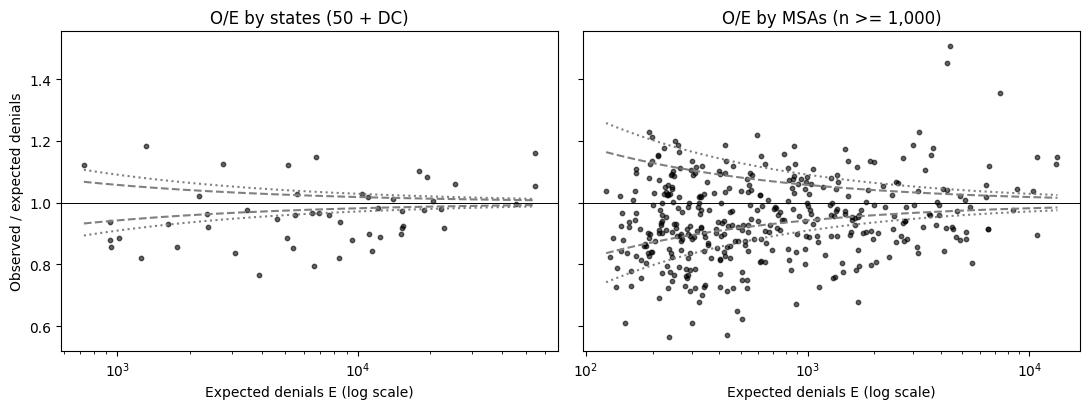

In [9]:
UG = U[U["in_universe"]]
ST = oe_table(UG, "state_code")
ST = ST[ST["n"] >= G["state_min_n"]]
lo, hi = wilson(ST["O"], ST["n"]); ST["ci_low"], ST["ci_high"] = lo, hi
ST["std_rate"] = ST["oe"] * U["y"].mean()
save(ST.sort_values("oe", ascending=False).reset_index(names="state_code"), "sq3_state_oe")
sep = oe_table(U[U["state_code"].astype(str).isin(G["report_separately"] + G["count_only"]) | U["state_missing"]], "state_code")
save(sep.reset_index(names="state_code"), "sq3_state_separate_lines")
if "NA" in sep.index:
    check("O/E nhóm thiếu bang", float(sep.loc["NA", "oe"]), "geography.missing_state_usable_oe")
print("dòng riêng (PR báo O/E; GU, VI chỉ đếm; NA thiếu vị trí):\n", sep[["n", "O", "raw_rate", "oe"]].round(3).to_string())
ds = dispersion(ST)
KEY.update({"states_universe": len(ST), "tau_state": ds["tau"], "sd_state_raw_rate": float(ST["raw_rate"].std(ddof=1)),
            "sd_state_std_rate": float(ST["std_rate"].std(ddof=1))})
check("số bang trong phạm vi", len(ST), "geography.universe_states")

msa_n = UG[UG["msa"] != R["special_codes"]["msa_nonmetro"]].groupby("msa").size()
MSA_SET = sorted(msa_n[msa_n >= TH["msa"]["min_usable"]].index)
KEY["msa_common"] = len(MSA_SET)
check("tập MSA chung", len(MSA_SET), "geography.msa_common_set")
MT = oe_table(UG[UG["msa"].isin(MSA_SET)], "msa")
dm = dispersion(MT)
med_loan = c[c["orig"] & c["in_universe"]].groupby("msa")["loan_amount_num"].median()
MT = MT.join(med_loan.rename("median_loan_originated"))
save(MT.sort_values("oe", ascending=False).reset_index(names="msa"), "sq3_msa_oe")
KEY.update({"tau_msa": dm["tau"], "msa_share_outside_95": dm["share_outside_95"]})

ctyU = UG[UG["county_valid"]]
CT = oe_table(ctyU, "county_code"); CT = CT[CT["n"] >= G["county_display_min_n"]]
dc = dispersion(CT) if len(CT) > 2 else {}
KEY.update({"counties_valid_core": int(c.loc[c["county_valid"], "county_code"].nunique()), "counties_display": len(CT)})
save(CT.reset_index(names="county_code"), "sq3_county_oe_display")

UL = UG[UG["lmi"].notna()].copy(); UL["lmi_group"] = np.where(UL["lmi"].astype(bool), "LMI", "other")
LM = oe_table(UL, "lmi_group")
LMt = pd.concat([oe_table(UL[UL["type"] == t_], "lmi_group").assign(loan_type=t_) for t_ in TYPE_ORDER])
lmi_k = pd.DataFrame([{**kitagawa(UL.assign(g=UL["lmi_group"]), "g", "LMI", "other"), "scope": "all"}] +
                     [{**kitagawa(UL[UL["type"] == t_].assign(g=lambda d: d["lmi_group"]), "g", "LMI", "other"), "scope": t_}
                      for t_ in ["conventional", "FHA", "VA"]])
save(LM.reset_index(names="lmi_group"), "sq3_lmi_oe"); save(LMt.reset_index(names="lmi_group"), "sq3_lmi_oe_by_type")
save(lmi_k, "sq3_lmi_kitagawa")
KEY.update({"oe_lmi": float(LM.loc["LMI", "oe"]), "oe_non_lmi": float(LM.loc["other", "oe"])})
o_l = c[c["orig"] & c["in_universe"] & c["lmi"].notna()]
la = o_l.groupby(np.where(o_l["lmi"].astype(bool), "LMI", "other"))["loan_amount_num"].median(); del o_l
save(la.rename("median_loan_originated").rename_axis("lmi_group").reset_index(), "sq3_lmi_loan_size")
print(f"bang: {len(ST)} | τ {ds['tau']:.3f} | MSA chung {len(MSA_SET)} | τ {dm['tau']:.3f} | O/E LMI {KEY['oe_lmi']:.3f} vs {KEY['oe_non_lmi']:.3f}")

# Hồ sơ thiếu vị trí (bằng chứng cho dòng chất lượng dữ liệu)
dec = c.loc[c["decisioned"], ["state_missing", "purpose", "tract_ratio", "denied"]]
grp = np.where(dec["state_missing"], "missing_state", "has_state")
mp = pd.crosstab(grp, dec["purpose"], normalize="index"); save(mp.reset_index(names="group"), "dq_missing_location_purpose_mix")
mt_ = (dec.assign(group=grp, tract_missing=np.isnan(dec["tract_ratio"]))
          .groupby(["group", "tract_missing"])["denied"].agg(n="size", denial_rate="mean").reset_index())
save(mt_, "dq_missing_location_by_tract")
print(mt_.round(3).to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
pbar = U["y"].mean()
for ax, t_, nm in [(axs[0], ST, "states (50 + DC)"), (axs[1], MT, f"MSAs (n >= {TH['msa']['min_usable']:,})")]:
    ax.scatter(t_["E"], t_["oe"], s=10, color="black", alpha=.6)
    xs = np.logspace(np.log10(t_["E"].min()), np.log10(t_["E"].max()), 200)
    for z, ls in [(1.96, "--"), (3.09, ":")]:
        se = np.sqrt(xs * (1 - pbar)) / xs
        ax.plot(xs, 1 + z * se, color="grey", ls=ls); ax.plot(xs, 1 - z * se, color="grey", ls=ls)
    ax.axhline(1, color="black", lw=.7); ax.set_xscale("log"); ax.set_xlabel("Expected denials E (log scale)")
    ax.set_title(f"O/E by {nm}")
axs[0].set_ylabel("Observed / expected denials")
plt.tight_layout(); plt.savefig(f"{FIG}/sq3_funnel_state_msa.png", dpi=150); show()

## 8. SQ4: lender (rules mục 9, 10, 15)
767 lender = >= 500 hồ sơ decisioned và >= 80% usable. O/E của lender dùng mọi hồ sơ usable của lender ở mọi vùng.

  lender >= 500 decisioned                                  812   kỳ vọng          812 (verified)  OK
  lender phân tích                                          767   kỳ vọng          767 (verified)  OK
lender: τ 0.502 | ngoài 95% 87.0% | ngoài 99.8% 77.8%
định nghĩa từ chối: Spearman 0.987 | đổi ngũ phân vị 0.142
                                       variant  groups   tau  tau_weighted
                                 cell_min_n=20     767 0.498         0.451
                                 cell_min_n=30     767 0.502         0.452
                                 cell_min_n=50     767 0.505         0.453
                        n_dec>=250, share>=0.8    1130 0.486         0.453
                        n_dec>=500, share>=0.8     767 0.502         0.452
                       n_dec>=1000, share>=0.8     483 0.496         0.446
                        n_dec>=500, share>=0.7     775 0.504         0.454
                        n_dec>=500, share>=0.8     767 0.502         0.452
        

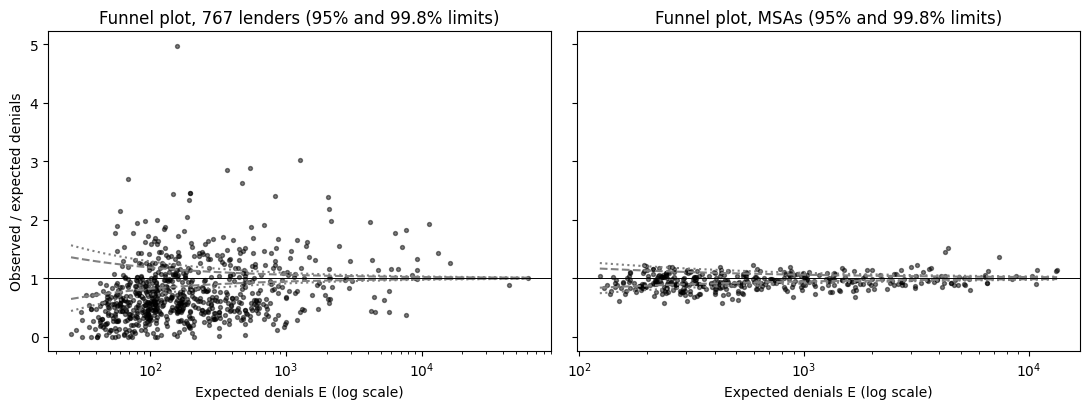

In [10]:
dl = c.loc[c["decisioned"], ["lei", "usable"]].groupby("lei", observed=True)["usable"].agg(n_dec="size", n_us="sum")
dl["us_share"] = dl["n_us"] / dl["n_dec"]
big812 = dl[dl["n_dec"] >= TH["lender"]["min_decisioned"]]
L767 = sorted(big812[big812["us_share"] >= TH["lender"]["min_usable_share"]].index.astype(str))
KEY.update({"lenders_812": len(big812), "lenders_812_share": float(big812["n_dec"].sum() / dl["n_dec"].sum()),
            "lenders_767": len(L767)})
check("lender >= 500 decisioned", len(big812), "lenders.min500_decisioned_only")
check("lender phân tích", len(L767), "lenders.analysis_set")

U["lei_s"] = U["lei"].astype(str)
LO = oe_table(U[U["lei_s"].isin(L767)], "lei_s")
dlen = dispersion(LO)
KEY.update({"tau_lender": dlen["tau"], "tau_lender_weighted": dlen["tau_weighted"], "lender_share_outside_95": dlen["share_outside_95"],
            "lender_share_outside_998": dlen["share_outside_998"], "lender_median_oe": dlen["median_oe"]})
print(f"lender: τ {dlen['tau']:.3f} | ngoài 95% {dlen['share_outside_95']:.1%} | ngoài 99.8% {dlen['share_outside_998']:.1%}")

# Tên từ Transmittal Sheet
ts = pd.read_csv(TS_PATH, dtype=str)[R["source"]["transmittal_sheet"]["columns"]] if TS_PATH else pd.DataFrame(columns=["lei"])
LO = LO.join(ts.drop_duplicates("lei").set_index("lei"), how="left")
LO["agency"] = LO["agency_code"].map(R["codes"]["agency_code"]) if "agency_code" in LO else None

# Trong từng loại vay
wt = []
for code_, nm in [("1", "conventional"), ("2", "FHA")]:
    sub_ = U[U["loan_type"].astype(str) == code_]
    t_ = oe_table(sub_, "lei_s"); t_ = t_[t_["n"] >= 500]
    d_ = dispersion(t_); d_["scope"] = f"within {nm}"; wt.append(d_)
    KEY[f"tau_lender_within_{nm}"] = d_["tau"]
    KEY[f"spearman_lender_oe_main_vs_within_{nm}"] = spearman(LO["oe"].reindex(t_.index), t_["oe"])

# Định nghĩa từ chối thay thế (812 lender, tỷ lệ thô)
apps = c.groupby("lei", observed=True)["action_taken"].value_counts().unstack(fill_value=0)
apps.index = apps.index.astype(str); apps.columns = apps.columns.astype(str)
for k_ in ["1", "2", "3", "4", "5"]:
    if k_ not in apps.columns:
        apps[k_] = 0
apps["rate_main"] = apps["3"] / (apps["1"] + apps["2"] + apps["3"])
apps["rate_alt"] = apps["3"] / (apps[["1", "2", "3", "4", "5"]].sum(axis=1))
apps["wd_inc_share"] = (apps["4"] + apps["5"]) / apps[["1", "2", "3", "4", "5"]].sum(axis=1)
s812 = apps.loc[big812.index.astype(str)]
q_main = ntile(s812["rate_main"].to_numpy(), s812.index.to_numpy())
q_alt = ntile(s812["rate_alt"].to_numpy(), s812.index.to_numpy())
KEY.update({"denial_def_spearman": spearman(s812["rate_main"], s812["rate_alt"]),
            "denial_def_share_changing_quintile": float((q_main != q_alt).mean())})
print(f"định nghĩa từ chối: Spearman {KEY['denial_def_spearman']:.3f} | đổi ngũ phân vị {KEY['denial_def_share_changing_quintile']:.3f}")

# Độ nhạy ngưỡng
sens = []
for mn in TH["sensitivity"]["cell_min_n"]:
    p_, _ = add_pext(U, mn)
    t_ = U.assign(p_ext=p_, v_ext=p_ * (1 - p_))
    sens.append({"variant": f"cell_min_n={mn}", **dispersion(oe_table(t_[t_["lei_s"].isin(L767)], "lei_s"))})
ALLO = oe_table(U, "lei_s").join(dl.set_axis(dl.index.astype(str)))
for nd in TH["sensitivity"]["lender_min_decisioned"]:
    sens.append({"variant": f"n_dec>={nd}, share>={TH['lender']['min_usable_share']}",
                 **dispersion(ALLO[(ALLO["n_dec"] >= nd) & (ALLO["us_share"] >= TH["lender"]["min_usable_share"])])})
for sh in TH["sensitivity"]["lender_min_usable_share"]:
    sens.append({"variant": f"n_dec>={TH['lender']['min_decisioned']}, share>={sh}",
                 **dispersion(ALLO[(ALLO["n_dec"] >= TH["lender"]["min_decisioned"]) & (ALLO["us_share"] >= sh)])})
# lender có phần lớn hồ sơ bị từ chối không usable (O bị đếm thiếu)
den_all = c[c["denied"]].groupby("lei", observed=True).size(); den_all.index = den_all.index.astype(str)
LO["den_usable_share"] = LO["O"] / den_all.reindex(LO.index)
for thr in (0.5, 0.3):
    keep_ = ~((den_all.reindex(LO.index) >= 10) & (LO["den_usable_share"] < thr))
    sens.append({"variant": f"drop lenders with >=10 denials and <{int(thr * 100)}% usable", **dispersion(LO[keep_])})
sens = pd.DataFrame(sens + [dict(variant="within " + w["scope"].split()[-1], **{k: v for k, v in w.items() if k != "scope"}) for w in wt])
save(sens, "sq4_sensitivity")
print(sens[["variant", "groups", "tau", "tau_weighted"]].round(3).to_string(index=False))

# Giá: phân tán rate spread đã chuẩn hóa rủi ro giữa lender và giữa MSA (SQ4).
# rules mục 23: spread kỳ vọng = trung bình ô rủi ro × loại vay × mục đích trong mẫu pricing ∩ usable;
# ô < 30 dùng trung bình ô rủi ro × loại vay (giữ loại vay vì APR của FHA có phí bảo hiểm).
SPREAD_MIN_GROUP_N = int(R["spread_dispersion"]["min_group_n"])
PS = c[c["pricing"] & c["usable"]][["lei", "msa", "in_universe", "rs_num"] + KEYS + ["loan_type", "loan_purpose"]].copy()
PS["lei_s"] = PS["lei"].astype(str)
gx = PS.groupby(EXTK, observed=True)["rs_num"]
gf = PS.groupby(KEYS + ["loan_type"], observed=True)["rs_num"]
PS["sres"] = PS["rs_num"] - np.where(gx.transform("size") >= R["extended_cells"]["min_n"], gx.transform("mean"), gf.transform("mean"))


def spread_tau(df, key):
    g_ = df.groupby(key, observed=True)["sres"].agg(n="size", mean="mean", var="var")
    g_ = g_[g_["n"] >= SPREAD_MIN_GROUP_N]
    v = float(g_["mean"].var(ddof=1)); s2 = float((g_["var"] / g_["n"]).mean())
    return {"groups": len(g_), "sd_mean": v ** .5, "tau": max(v - s2, 0) ** .5}


sp_l = spread_tau(PS[PS["lei_s"].isin(L767)], "lei_s")
sp_m = spread_tau(PS[PS["in_universe"] & PS["msa"].isin(MSA_SET)], "msa")
KEY.update({"spread_tau_lender": sp_l["tau"], "spread_tau_msa": sp_m["tau"], "spread_groups_lender": sp_l["groups"],
            "spread_groups_msa": sp_m["groups"], "spread_sd_lender": sp_l["sd_mean"], "spread_sd_msa": sp_m["sd_mean"],
            "lenders_zero_denials": int((LO["O"] == 0).sum())})
save(pd.DataFrame([dict(group="lender", **sp_l), dict(group="msa", **sp_m)]), "sq4_spread_dispersion")
check("lender không có hồ sơ từ chối (trong 767)", KEY["lenders_zero_denials"], "lenders.zero_denials_in_767")
print(f"rate spread chuẩn hóa: τ lender {sp_l['tau']:.3f} điểm % ({sp_l['groups']} nhóm) | τ MSA {sp_m['tau']:.3f} ({sp_m['groups']} nhóm)")
del PS

# Độ nhạy: DTI 5 nhóm (rules 1.1, risk_cells.sensitivity_dti_bands)
U["dti_band_alt"] = bands(U["dti_ordinal"], D[R["risk_cells"]["sensitivity_dti_bands"]])
KA = ["dti_band_alt", "cltv_band", "lti_band"]; EA = KA + ["loan_type", "loan_purpose"]
g_ = U.groupby(EA, observed=True)["y"]
p_alt = np.where(g_.transform("size") >= R["extended_cells"]["min_n"], g_.transform("mean"),
                 U.groupby(KA, observed=True)["y"].transform("mean"))
TA = U[["lei_s", "y", "loan_type"] + KA].assign(p_ext=p_alt, v_ext=p_alt * (1 - p_alt))
LOA = oe_table(TA[TA["lei_s"].isin(L767)], "lei_s")
kA = kitagawa(TA, "loan_type", "2", "1", keys=KA)
KEY.update({"dti5_n_risk_cells": int(TA.groupby(KA, observed=True).ngroups),
            "dti5_smallest_cell_n": int(TA.groupby(KA, observed=True).size().min()),
            "dti5_national_oe": float(TA["y"].sum() / TA["p_ext"].sum()), "dti5_tau_lender": dispersion(LOA)["tau"],
            "dti5_spearman_lender_oe": spearman(LO["oe"], LOA["oe"].reindex(LO.index))})
for k in ["gap", "composition", "rate", "rate_gap_at_a_mix", "rate_gap_at_b_mix", "cells_a_higher", "cells_a_lower"]:
    KEY[f"dti5_kitagawa_loan_type_2v1_{k}"] = kA[k]
d5 = {k: v for k, v in KEY.items() if k.startswith("dti5_")}
save(pd.Series(d5).rename("value").rename_axis("key").reset_index(), "sq4_dti5_sensitivity")
print("DTI 5 nhóm:", {k: round(float(v), 4) for k, v in d5.items()})
del TA, g_, p_alt

# Bỏ hồ sơ fallback
LOnf = oe_table(U[U["lei_s"].isin(L767) & ~U["fallback"]], "lei_s")
d_oe = (LOnf["oe"] - LO["oe"].reindex(LOnf.index)).abs()
KEY.update({"fallback_robust_max_abs_change": float(d_oe.max()), "fallback_robust_spearman": spearman(LO["oe"].reindex(LOnf.index), LOnf["oe"])})
print(f"bỏ fallback: |ΔO/E| lớn nhất {KEY['fallback_robust_max_abs_change']:.4f} | Spearman {KEY['fallback_robust_spearman']:.4f}")

# Bảng cực trị
dd = c.loc[c["decisioned"], ["lei", "loan_type", "loan_purpose"]]
def dominant(col):
    t_ = dd.groupby([dd["lei"].astype(str), dd[col].astype(str)]).size().rename("c").reset_index()
    t_.columns = ["lei", "val", "c"]
    t_ = t_.sort_values(["lei", "c", "val"], ascending=[True, False, True]).drop_duplicates("lei").set_index("lei")
    return t_["val"], t_["c"] / dl.set_axis(dl.index.astype(str))["n_dec"].reindex(t_.index)


tt, ts_ = dominant("loan_type"); tp, tps = dominant("loan_purpose")
LO["dominant_loan_type"] = tt.reindex(LO.index).map(LT_NAME); LO["dominant_loan_type_share"] = ts_.reindex(LO.index)
LO["dominant_purpose"] = tp.reindex(LO.index).map(LP_NAME); LO["dominant_purpose_share"] = tps.reindex(LO.index)
LO["withdrawn_incomplete_share"] = apps["wd_inc_share"].reindex(LO.index)
LO["denial_rate_main"] = apps["rate_main"].reindex(LO.index); LO["denial_rate_alternative"] = apps["rate_alt"].reindex(LO.index)
LO["n_usable"] = LO["n"]
ex_cols = R["observed_expected"]["extremes_table"]["columns"]
srt = LO.reset_index(names="lei").sort_values(["oe", "lei"])
k_ = R["observed_expected"]["extremes_table"]["n_each_side"]
extremes = pd.concat([srt.head(k_).assign(side="lowest"), srt.tail(k_).iloc[::-1].assign(side="highest")])
save(extremes[["side"] + [x for x in ex_cols if x in extremes.columns]], "sq4_lender_extremes")
save(LO.reset_index(names="lei"), "sq4_lender_oe")
print(extremes[["side", "respondent_name", "n_usable", "oe", "dominant_loan_type", "withdrawn_incomplete_share"]].round(3).to_string(index=False))
if "agency" in LO:
    ag = LO.groupby("agency")["oe"].agg(n="size", median="median").reset_index(); save(ag, "sq4_oe_by_agency")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, t_, nm in [(axs[0], LO, f"{len(L767)} lenders"), (axs[1], MT, "MSAs")]:
    ax.scatter(t_["E"], t_["oe"], s=8, color="black", alpha=.5)
    xs = np.logspace(np.log10(max(t_["E"].min(), 1)), np.log10(t_["E"].max()), 200)
    for z, ls in [(1.96, "--"), (3.09, ":")]:
        se = np.sqrt(xs * (1 - pbar)) / xs
        ax.plot(xs, 1 + z * se, color="grey", ls=ls); ax.plot(xs, np.maximum(1 - z * se, 0), color="grey", ls=ls)
    ax.axhline(1, color="black", lw=.7); ax.set_xscale("log"); ax.set_xlabel("Expected denials E (log scale)")
    ax.set_title(f"Funnel plot, {nm} (95% and 99.8% limits)")
axs[0].set_ylabel("Observed / expected denials")
plt.tight_layout(); plt.savefig(f"{FIG}/sq4_funnel_lender_msa.png", dpi=150); show()

## 9. Mô hình hai chiều lender + MSA và HHI (rules mục 13, 14)
Thứ tự lọc đúng rules. Hiệu ứng ước lượng ở cấp ô lender × MSA (tổng phần dư S và số hồ sơ n), 40 vòng cố định.
Split-half tất định: h = ((row_id + 2024) × 2654435761) mod 2^32, sắp theo (h, row_id) trong từng ô, chia xen kẽ.

In [11]:
S_ = R["sampling"]
TW = U[U["in_universe"] & U["msa"].isin(MSA_SET) & U["lei_s"].isin(L767)][["row_id", "lei_s", "msa", "y", "p_ext"]].copy()
TW["r"] = TW["y"] - TW["p_ext"]
TW["li"] = TW["lei_s"].astype("category").cat.codes.astype(np.int64)
TW["mi"] = TW["msa"].astype("category").cat.codes.astype(np.int64)
lei_cats = TW["lei_s"].astype("category").cat.categories; msa_cats = TW["msa"].astype("category").cat.categories
nL, nM = len(lei_cats), len(msa_cats)

# thành phần liên thông lớn nhất (union-find trên cặp lender - MSA)
pairs = TW[["li", "mi"]].drop_duplicates().to_numpy()
parent = np.arange(nL + nM)
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for a_, b_ in pairs:
    ra, rb = find(a_), find(nL + b_)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)
root = np.array([find(i) for i in range(nL + nM)])
lab_l = root[TW["li"].to_numpy()]
big_root = pd.Series(lab_l).value_counts().idxmax()
TW = TW[lab_l == big_root].copy()
present = np.concatenate([np.unique(pairs[:, 0]), nL + np.unique(pairs[:, 1])])
KEY.update({"twoway_components": int(len(set(root[present]))), "twoway_lenders": int(TW["li"].nunique()),
            "twoway_msas": int(TW["mi"].nunique()), "twoway_records": len(TW)})


def cell_agg(df):
    return df.groupby(["li", "mi"]).agg(n=("r", "size"), S=("r", "sum")).reset_index()


def fit(cells, iters=R["two_way_effects"]["iterations"]):
    li, mi = cells["li"].to_numpy(), cells["mi"].to_numpy()
    n, S = cells["n"].to_numpy(float), cells["S"].to_numpy(float)
    nl, nm = np.bincount(li, n, nL), np.bincount(mi, n, nM)
    a, b = np.zeros(nL), np.zeros(nM)
    for _ in range(iters):
        a = np.divide(np.bincount(li, S - n * b[mi], nL), nl, out=np.zeros(nL), where=nl > 0)
        b = np.divide(np.bincount(mi, S - n * a[li], nM), nm, out=np.zeros(nM), where=nm > 0)
    return a, b, nl, nm


def wsd(x, w):
    m = np.average(x, weights=w); return float(np.sqrt(np.average((x - m) ** 2, weights=w)))


def wcov(x, y, w):
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    return float(np.average((x - mx) * (y - my), weights=w))


a, b, nl, nm = fit(cell_agg(TW))
inL, inM = nl > 0, nm > 0
SPLIT_SEED = 2024
assert f"row_id + {SPLIT_SEED}" in R["two_way_effects"]["split_half"]["hash"]
TW["h"] = ((TW["row_id"] + SPLIT_SEED) * S_["hash_multiplier"]) % S_["hash_modulus"]
TW = TW.sort_values(["li", "mi", "h", "row_id"])
TW["half"] = (TW.groupby(["li", "mi"]).cumcount() % 2).astype(np.int8)
a0, b0, nl0, nm0 = fit(cell_agg(TW[TW["half"] == 0]))
a1, b1, nl1, nm1 = fit(cell_agg(TW[TW["half"] == 1]))
okL, okM = inL & (nl0 > 0) & (nl1 > 0), inM & (nm0 > 0) & (nm1 > 0)
mpl = TW.groupby("li")["mi"].nunique()
KEY.update({
    "twoway_lender_full_sd": wsd(a[inL], nl[inL]), "twoway_msa_full_sd": wsd(b[inM], nm[inM]),
    "twoway_lender_signal_sd": max(wcov(a0[okL], a1[okL], nl[okL]), 0) ** .5,
    "twoway_msa_signal_sd": max(wcov(b0[okM], b1[okM], nm[okM]), 0) ** .5,
    "twoway_median_msas_per_lender": float(mpl.median()), "twoway_share_lenders_le2_msas": float((mpl <= 2).mean()),
    "twoway_lenders_both_halves": int(okL.sum()), "twoway_msas_both_halves": int(okM.sum())})
tw_out = {k: v for k, v in KEY.items() if k.startswith("twoway_")}
pd.Series(tw_out).to_csv(f"{RES}/sq4_two_way.csv", header=["value"])
pd.DataFrame({"lei": lei_cats[inL], "effect": a[inL], "n": nl[inL]}).to_csv(f"{RES}/sq4_two_way_lender_effects.csv", index=False)
pd.DataFrame({"msa": msa_cats[inM], "effect": b[inM], "n": nm[inM]}).to_csv(f"{RES}/sq4_two_way_msa_effects.csv", index=False)
print(json.dumps({k: (round(v * 100, 3) if "sd" in k else v) for k, v in tw_out.items()}, indent=1))

# HHI: originations trong core, phạm vi địa lý, tập MSA chung, mọi lender
og = c[c["orig"] & c["in_universe"] & c["msa"].isin(MSA_SET)]
cnt_ = og.groupby(["msa", og["lei"].astype(str)]).size().rename("n").reset_index()
cnt_["share"] = cnt_["n"] / cnt_.groupby("msa")["n"].transform("sum")
hhi = (cnt_.assign(s2=cnt_["share"] ** 2).groupby("msa")["s2"].sum() * 10000)
H = pd.DataFrame({"hhi": hhi}).join(MT["oe"])
save(H.reset_index(names="msa"), "sq4_hhi_msa")
KEY.update({"hhi_median": float(H["hhi"].median()), "hhi_p10": float(H["hhi"].quantile(.1)), "hhi_p90": float(H["hhi"].quantile(.9)),
            "hhi_spearman_oe": spearman(H["hhi"], H["oe"]), "hhi_msas": len(H)})
print(f"HHI: trung vị {KEY['hhi_median']:.0f} (p10 {KEY['hhi_p10']:.0f}, p90 {KEY['hhi_p90']:.0f}) | Spearman với O/E {KEY['hhi_spearman_oe']:.3f}")

{
 "twoway_components": 1,
 "twoway_lenders": 764,
 "twoway_msas": 392,
 "twoway_records": 3266906,
 "twoway_lender_full_sd": 7.07,
 "twoway_msa_full_sd": 1.637,
 "twoway_lender_signal_sd": 7.06,
 "twoway_msa_signal_sd": 1.61,
 "twoway_median_msas_per_lender": 55.0,
 "twoway_share_lenders_le2_msas": 0.002617801047120419,
 "twoway_lenders_both_halves": 764,
 "twoway_msas_both_halves": 392
}
HHI: trung vị 401 (p10 261, p90 685) | Spearman với O/E -0.159


## 10. Sáu đầu ra cho kiểm tra tương đương (rules mục 19)
Định dạng cột giống hệt bên PySpark. Script `check_equivalence.py` đọc các file `eq_*.csv` của hai bên.

In [12]:
steps = [("all_records", n_all)] + [(f["step"], step_counts[f["step"]]) for f in FILT] + [
    ("open_end_exempt_removed", open_end_exempt_removed), ("decisioned", int(c["decisioned"].sum())),
    ("usable", int(c["usable"].sum())), ("pricing", int(c["pricing"].sum())),
    ("pricing_usable", int((c["pricing"] & c["usable"]).sum()))]
save(pd.DataFrame(steps, columns=["step", "rows"]), "eq_1_filter_counts")
save(dq, "eq_2_special_codes")
save(fprof[["field"] + [x if x else "(empty)" for x in FP["count_codes"]] + ["numeric"]], "eq_2b_field_profile")
a3 = pd.DataFrame(sorted(act_counts.items()), columns=["action_taken", "n"]); a3["share"] = a3["n"] / n_all
save(a3, "eq_3_action_taken")

dec = c.loc[c["decisioned"], ["loan_type", "income_num", "loan_amount_num", "state_code", "denied", "lei", "usable"]]
rows4 = []
for var, src, s_df in [("income", "income_num", dec), ("loan_amount", "loan_amount_num", dec), ("rate_spread", "rs_num", c.loc[c["pricing"], ["loan_type", "rs_num"]])]:
    for lt_code, g_ in s_df.groupby(s_df["loan_type"].astype(str)):
        x_ = g_[src].dropna()
        rows4.append({"sample": "pricing" if var == "rate_spread" else "decisioned", "variable": var, "loan_type": lt_code,
                      "n": len(x_), "mean": float(x_.mean()), "median_exact": float(x_.median()), "median_approx": np.nan})
save(pd.DataFrame(rows4), "eq_4_amounts_by_loan_type")
oo = c.loc[c["orig"], ["loan_type", "rs_num", "rate_spread", "rs_out_of_range", "rs_valid"]]
rc = (pd.DataFrame({"loan_type": oo["loan_type"].astype(str).to_numpy(), "numeric": oo["rs_num"].notna().to_numpy(),
                    "na": (oo["rate_spread"].astype(str) == "NA").to_numpy(), "exempt": (oo["rate_spread"].astype(str) == "Exempt").to_numpy(),
                    "out_of_range": oo["rs_out_of_range"].to_numpy(), "valid": oo["rs_valid"].to_numpy()})
        .groupby("loan_type").sum().astype(int).reset_index())
save(rc, "eq_4b_rate_spread_counts")
s5 = dec.groupby(dec["state_code"].astype(str)).agg(n_decisioned=("denied", "size"), n_denied=("denied", "sum")).reset_index()
s5["denial_rate"] = s5["n_denied"] / s5["n_decisioned"]
save(s5, "eq_5_denial_by_state")
t6 = dec.groupby(dec["lei"].astype(str)).agg(n_decisioned=("denied", "size"), n_denied=("denied", "sum"),
                                              mean_income=("income_num", "mean"), mean_loan_amount=("loan_amount_num", "mean"),
                                              n_usable=("usable", "sum")).reset_index().rename(columns={"index": "lei"})
t6 = t6.sort_values(["n_decisioned", "lei"], ascending=[False, True]).head(50)
t6["denial_rate"] = t6["n_denied"] / t6["n_decisioned"]
oe_all = oe_table(U, "lei_s")[["O", "E", "oe"]]
t6 = t6.join(oe_all, on="lei"); t6.insert(0, "rank", range(1, len(t6) + 1))
save(t6, "eq_6_top50_lenders")
print("đã ghi eq_1 .. eq_6")

đã ghi eq_1 .. eq_6


## 11. Mô hình dự đoán (rules mục 20)
Chỉ hồ sơ usable, không imputation; không dùng giới tính, chủng tộc, dân tộc, tuổi, lender, vị trí, biến sau quyết định.
5 fold chia theo lender bằng SHA-256 của `lei` (Python và Spark ra cùng fold). Mỗi fold dự đoán bằng mô hình học trên
4 fold còn lại (cross-fitting), nên mọi hồ sơ đều có xác suất ngoài mẫu. Logistic regression làm mốc; mô hình cây là
HistGradientBoosting của scikit-learn. Mô hình chỉ được dùng nếu đạt tiêu chí calibration của rules.

  fold 0: train 3,133,823 | test 966,228 | 77s
  fold 1: train 3,488,807 | test 611,244 | 153s
  fold 2: train 3,140,918 | test 959,133 | 223s
  fold 3: train 3,358,281 | test 741,770 | 297s
  fold 4: train 3,278,375 | test 821,676 | 374s
model  roc_auc  pr_auc  brier  calibration_in_the_large  calibration_slope  passes
 p_lr   0.8047  0.5482 0.0886                    0.0009             0.9815    True
p_gbt   0.8356  0.6248 0.0795                    0.0002             0.9862    True


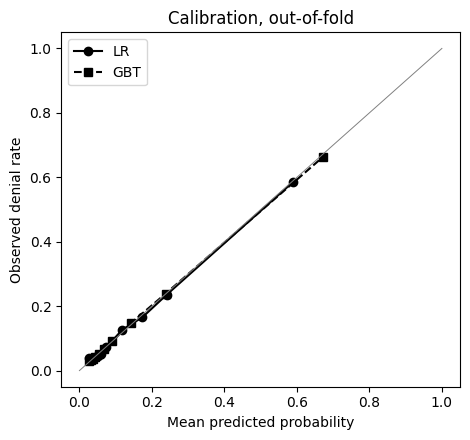

{'pred_spearman_cells_vs_lr': 0.9829, 'pred_spearman_cells_vs_gbt': 0.9858}
             denied  approved
dti_ordinal   0.107     0.046
cltv          0.082     0.044
income_num    0.043     0.046
term_num      0.036     0.001
dự đoán xong | 389s


In [13]:
if RUN_PREDICTION:
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

    t0 = time.time()
    PR = R["prediction"]
    M = U[["row_id", "lei_s", "y", "dti_ordinal", "cltv", "lti", "loan_amount_num", "income_num", "loan_type", "loan_purpose"]].copy()
    fold_of = {l: int(hashlib.sha256(l.encode()).hexdigest()[:8], 16) % PR["folds"]["k"] for l in M["lei_s"].unique()}
    M["fold"] = M["lei_s"].map(fold_of).astype(int)
    # Logistic: DTI và nhóm CLTV dạng one-hot (quan hệ không tuyến tính), các biến tiền dạng log
    cat_lr = pd.get_dummies(pd.DataFrame({"dti": M["dti_ordinal"].astype(int).astype(str),
                                          "cltvb": U["cltv_band"].astype(str), "lt": M["loan_type"].astype(str),
                                          "lp": M["loan_purpose"].astype(str)}), drop_first=True, dtype=np.float32)
    num_lr = pd.DataFrame({"cltv": np.clip(M["cltv"], 0, 150) / 100, "log_lti": np.log(np.clip(M["lti"], 0.05, 20)),
                           "log_amt": np.log(M["loan_amount_num"]), "log_inc": np.log(np.clip(M["income_num"], 1, None))})
    num_lr = (num_lr - num_lr.mean()) / num_lr.std()
    X_lr = np.hstack([num_lr.to_numpy(np.float32), cat_lr.to_numpy(np.float32)])
    X_gb = np.column_stack([M["dti_ordinal"], M["cltv"], M["lti"], M["loan_amount_num"], M["income_num"],
                            M["loan_type"].astype(str).astype(int), M["loan_purpose"].astype(str).astype(int)]).astype(np.float32)
    y = M["y"].to_numpy()
    M["p_lr"], M["p_gbt"] = np.nan, np.nan
    for k in range(PR["folds"]["k"]):
        tr_, te_ = (M["fold"] != k).to_numpy(), (M["fold"] == k).to_numpy()
        lr = LogisticRegression(max_iter=300, C=1e4).fit(X_lr[tr_], y[tr_])
        M.loc[te_, "p_lr"] = lr.predict_proba(X_lr[te_])[:, 1]
        gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, categorical_features=[5, 6],
                                            early_stopping=False, random_state=2024).fit(X_gb[tr_], y[tr_])
        M.loc[te_, "p_gbt"] = gb.predict_proba(X_gb[te_])[:, 1]
        print(f"  fold {k}: train {tr_.sum():,} | test {te_.sum():,} | {time.time() - t0:.0f}s")

    def calib_slope(p, yy):
        z = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))).reshape(-1, 1)
        return float(LogisticRegression(C=1e6, max_iter=200).fit(z, yy).coef_[0, 0])

    met = []
    crit = PR["use_only_if"]
    for m_ in ["p_lr", "p_gbt"]:
        p = M[m_].to_numpy()
        row = {"model": m_, "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
               "brier": brier_score_loss(y, p), "calibration_in_the_large": float(p.mean() - y.mean()),
               "calibration_slope": calib_slope(p, y)}
        row["passes"] = bool(abs(row["calibration_in_the_large"]) < 0.005 and 0.9 <= row["calibration_slope"] <= 1.1)
        met.append(row)
        for kk in ["roc_auc", "pr_auc", "brier", "calibration_in_the_large", "calibration_slope"]:
            KEY[f"pred_{m_}_{kk}"] = row[kk]
    met = pd.DataFrame(met); save(met, "pred_metrics")
    print(met.round(4).to_string(index=False))

    # bảng calibration theo thập phân vị, so lender O/E theo mô hình và theo ô
    cal = []
    for m_ in ["p_lr", "p_gbt"]:
        dcl = pd.qcut(M[m_], 10, labels=False, duplicates="drop")
        cal.append(M.groupby(dcl).agg(mean_pred=(m_, "mean"), observed=("y", "mean"), n=("y", "size")).assign(model=m_))
    cal = pd.concat(cal).reset_index(names="decile"); save(cal, "pred_calibration_deciles")
    fig, ax = plt.subplots(figsize=(4.8, 4.5))
    for m_, mk in [("p_lr", "o"), ("p_gbt", "s")]:
        q_ = cal[cal["model"] == m_]; ax.plot(q_["mean_pred"], q_["observed"], marker=mk, color="black", ls="-" if m_ == "p_lr" else "--", label=m_[2:].upper())
    ax.plot([0, 1], [0, 1], color="grey", lw=.7); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed denial rate")
    ax.set_title("Calibration, out-of-fold"); ax.legend(); plt.tight_layout(); plt.savefig(f"{FIG}/pred_calibration.png", dpi=150); show()

    cmp_ = LO[["oe"]].rename(columns={"oe": "oe_cells"})
    for m_ in ["p_lr", "p_gbt"]:
        g_ = M[M["lei_s"].isin(L767)].groupby("lei_s").agg(O=("y", "sum"), E=(m_, "sum"))
        cmp_[f"oe_{m_[2:]}"] = (g_["O"] / g_["E"]).reindex(cmp_.index)
        KEY[f"pred_spearman_cells_vs_{m_[2:]}"] = spearman(cmp_["oe_cells"], cmp_[f"oe_{m_[2:]}"])
    save(cmp_.reset_index(names="lei"), "pred_lender_oe_comparison")
    print({k: round(v, 4) for k, v in KEY.items() if k.startswith("pred_spearman")})
    M[["row_id", "lei_s", "fold", "y", "p_lr", "p_gbt"]].rename(columns={"lei_s": "lei"}).to_parquet(f"{RES}/pred_oof.parquet", index=False)
    pd.Series(fold_of).rename("fold").to_csv(f"{RES}/pred_folds_by_lei.csv", index_label="lei")
    # rò rỉ: tỷ lệ thiếu theo kết quả (decisioned core), lý do chỉ học trên hồ sơ đủ dữ liệu
    lk = pd.DataFrame({col: [c.loc[c["denied"], col].isna().mean(), c.loc[c["decisioned"] & ~c["denied"], col].isna().mean()]
                       for col in ["dti_ordinal", "cltv", "income_num", "term_num"]}, index=["denied", "approved"]).T
    save(lk.reset_index(names="field"), "pred_missingness_by_outcome")
    print(lk.round(3).to_string())
    print(f"dự đoán xong | {time.time() - t0:.0f}s")

## 12. Tổng kết
`key_numbers.json` chứa mọi số chính (cùng tên khóa với bên PySpark). `checks_vs_expected.csv` ghi kết quả so với expected.yaml.

In [14]:
def clean_json(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    return v


KEY["runtime_s"] = round(time.time() - T_START, 1)
json.dump({k: clean_json(v) for k, v in KEY.items()}, open(f"{RES}/key_numbers.json", "w"), indent=1, ensure_ascii=False)
pd.DataFrame(CHECKS).to_csv(f"{RES}/checks_vs_expected.csv", index=False)
bad = [x for x in CHECKS if x["match"] is False]
print(f"xong sau {KEY['runtime_s']:.0f}s | {len(CHECKS)} kiểm tra, {len(bad)} lệch so với expected.yaml")
for x in bad:
    print("  LỆCH:", x["check"], x["value"], "kỳ vọng", x["expected"])

xong sau 818s | 48 kiểm tra, 0 lệch so với expected.yaml
